In [1]:
# os: check if a file exists and make folders
import os
# pandas: tables (DataFrames)
import pandas as pd
# numpy: maths, e.g. log10 and NaN (missing value)
import numpy as np
# matplotlib: draws the charts
import matplotlib.pyplot as plt
# truststore: lets Python use Windows' certificates for HTTPS downloads
import truststore
truststore.inject_into_ssl()  # fixes CERTIFICATE_VERIFY_FAILED on Windows

# the .xlsx files are only the data dictionaries; the real data comes from the NYC Open Data API
# download once and save locally, so re-runs read the CSV instead of downloading again
# the 14 permit columns we need (out of 38), so the download is smaller
permit_cols = "job_filing_number,work_type,filing_reason,permit_status,borough,zip_code,c_b_no,latitude,longitude,approved_date,issued_date,expired_date,estimated_job_costs,job_description"
# permits API link: up to 1,000,000 rows, only permits issued from 2022 on, only those columns
permits_url = "https://data.cityofnewyork.us/resource/rbx6-tga4.csv?$limit=1000000&$where=issued_date>='2022-01-01'&$select=" + permit_cols
# crashes API link: up to 1,000,000 rows, only crashes from 2022 on, all columns
crashes_url = "https://data.cityofnewyork.us/resource/h9gi-nx95.csv?$limit=1000000&$where=crash_date>='2022-01-01'"

# download permits only if we don't already have the file
if not os.path.exists("permits.csv"):
    pd.read_csv(permits_url).to_csv("permits.csv", index=False)
# download crashes only if we don't already have the file
if not os.path.exists("crashes.csv"):
    pd.read_csv(crashes_url).to_csv("crashes.csv", index=False)

# read both saved files into tables (df_dob = permits, df_mv = motor vehicle crashes)
df_dob = pd.read_csv("permits.csv", low_memory=False)
df_mv = pd.read_csv("crashes.csv", low_memory=False)
# rows and columns of each table
print(df_dob.shape, df_mv.shape)

(432929, 14) (447156, 29)


# Dataset overview

## 1. Housing: H3 DOB NOW: Build – Approved Permits
- **Link:** https://data.cityofnewyork.us/d/rbx6-tga4
- **1 row =** one approved work permit. One job can have several rows (renewals).
- **What we loaded:** permits issued from 2022-01-01 (`$where`) and only the 14 columns we need out of 38 (`$select`). The full dataset goes back years before 2022 and is too big to load whole. 2022+ also matches the crash window.
- **Time columns:** issued_date, expired_date, approved_date
- **Geo columns:** borough, zip_code, latitude, longitude (c_b_no = community district)
- **Columns we use:** work_type, issued_date, expired_date, estimated_job_costs, latitude, longitude, job_filing_number
- **Known issues (found in EDA below):** renewals repeat the same job_filing_number; some rows miss lat/lon/ZIP; $0 and $1 placeholder costs; some permits expire before they start or have no expiry; "No Work Permit" rows; borough written in different cases.

In [2]:
# how many rows and columns the permits table has
print(df_dob.shape)
# the first and last issue date, to see what time span we loaded
print(df_dob['issued_date'].min(), df_dob['issued_date'].max())
# how many values are missing in the location and date columns
df_dob[['borough', 'zip_code', 'latitude', 'longitude', 'issued_date', 'expired_date']].isna().sum()

(432929, 14)
2022-01-01T00:00:00.000 2026-10-16T00:00:00.000


borough            0
zip_code         628
latitude        2158
longitude       2158
issued_date        0
expired_date     449
dtype: int64

## 2. Transportation: T4 Motor Vehicle Collisions – Crashes
- **Link:** https://data.cityofnewyork.us/d/h9gi-nx95
- **Catalog note:** the catalog lists T4 as "SIRTA Data" with crash borough, ZIP, lat/lon and crash date. This NYPD crash table has exactly those fields.
- **1 row =** one crash reported by police.
- **What we loaded:** crashes from 2022-01-01 (`$where`), all 29 columns. Same reason and same window as the permits.
- **Time columns:** crash_date, crash_time
- **Geo columns:** borough, zip_code, latitude, longitude, street names
- **Columns we use:** injuries by type (pedestrian / cyclist / motorist), contributing_factor_vehicle_1, vehicle_type_code1, crash hour, latitude, longitude
- **Known issues (found in EDA below):** many blank borough and ZIP; lat/lon missing or 0; messy vehicle labels ("E-BIK", "BOX T"); typo "Illnes".

In [3]:
# how many rows and columns the crashes table has
print(df_mv.shape)
# the first and last crash date, to see what time span we loaded
print(df_mv['crash_date'].min(), df_mv['crash_date'].max())
# how many values are missing in the location and time columns
df_mv[['borough', 'zip_code', 'latitude', 'longitude', 'crash_date', 'crash_time']].isna().sum()

(447156, 29)
2022-01-01T00:00:00.000 2026-10-31T00:00:00.000


borough       101271
zip_code      125794
latitude       24521
longitude      24521
crash_date         0
crash_time         0
dtype: int64

## Why these two
**Question:** is the street around street work (sidewalk sheds, scaffolds, fences, demolition) more dangerous while the work is active?

It matters because sheds and fences push people off the sidewalk and block drivers' view, and some sheds stay up for years. Both datasets have exact lat/lon and dates, so we can connect them at block level, not just by borough.

Rejected: affordable housing × crashes (only shows dense areas have more of everything), taxis (weak link to housing, huge files), bike counts (only a few count sites).

## How we connect them
- No shared key, and different shapes: a permit lasts months, a crash is one moment. So we do **not** match row to row.
- Both go on the same **~100 m square** (lat/lon rounded to 3 decimals) **× month** grid.
- A square-month is **active** if any street-work permit there was running that month. Crashes are counted per square-month.
- **Why 100 m:** about one city block, so it is the street around the site. ZIP or borough is too big and would hide the effect.
- Built in the Merge and Post-merge sections below.

# Permits (DOB NOW: Build – Approved Permits)

In [4]:
# show the first 5 rows so we can see what the data looks like
df_dob.head()

,job_filing_number,work_type,filing_reason,permit_status,borough,zip_code,c_b_no,latitude,longitude,approved_date,issued_date,expired_date,estimated_job_costs,job_description
0,M00923249-I1,General Construction,Renewal Permit Without Changes,Signed-off,MANHATTAN,10003.0,102.0,40.733707,-73.990994,2024-01-09T00:00:00.000,2024-05-16T00:00:00.000,2024-09-02T04:00:00.000,100000.0,EXTERIOR RENOVATION WORK INCLUDING REMOVAL OF ...
1,M01360498-I1,General Construction,Initial Permit,Permit Issued,Manhattan,10002.0,103.0,40.719143,-73.986984,2026-04-10T00:00:00.000,2026-05-18T00:00:00.000,2026-12-31T05:00:00.000,185040.0,APPLICATION FOR FACADE AND LEAK REPAIRS AS PER...
2,M00629731-I1,Standpipe,Initial Permit,Signed-off,MANHATTAN,10028.0,108.0,40.775767,-73.952817,2021-12-20T00:00:00.000,2023-05-17T00:00:00.000,2024-05-17T04:00:00.000,1000.0,PROVIDE SPRINKLER AND STANDPIPE SYSTEMS FOR PR...
3,X01078056-I1,General Construction,Renewal Permit Without Changes,Signed-off,BRONX,10471.0,208.0,40.903495,-73.900772,2025-01-13T00:00:00.000,2026-04-21T00:00:00.000,2026-06-28T00:00:00.000,225400.0,Garage repairs as per plans; no change to occu...
4,Q01292720-S1,Construction Fence,Initial Permit,Signed-off,Queens,11422.0,413.0,40.656137,-73.744503,2025-10-01T00:00:00.000,2025-12-29T00:00:00.000,2026-12-29T05:00:00.000,4500.0,INSTALLATION OF TEMPORARY CONSTRUCTION FENCE I...


In [5]:
# list every column name
df_dob.columns.tolist()

['job_filing_number',
 'work_type',
 'filing_reason',
 'permit_status',
 'borough',
 'zip_code',
 'c_b_no',
 'latitude',
 'longitude',
 'approved_date',
 'issued_date',
 'expired_date',
 'estimated_job_costs',
 'job_description']

In [6]:
# column types and how many non-empty values each column has
df_dob.info()

<class 'pandas.DataFrame'>
RangeIndex: 432929 entries, 0 to 432928
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   job_filing_number    432894 non-null  str    
 1   work_type            432929 non-null  str    
 2   filing_reason        432775 non-null  str    
 3   permit_status        432929 non-null  str    
 4   borough              432929 non-null  str    
 5   zip_code             432301 non-null  float64
 6   c_b_no               428564 non-null  float64
 7   latitude             430771 non-null  float64
 8   longitude            430771 non-null  float64
 9   approved_date        432929 non-null  str    
 10  issued_date          432929 non-null  str    
 11  expired_date         432480 non-null  str    
 12  estimated_job_costs  432929 non-null  float64
 13  job_description      432912 non-null  str    
dtypes: float64(5), str(9)
memory usage: 154.9 MB


In [7]:
# count the missing values in each column
df_dob.isnull().sum()

job_filing_number        35
work_type                 0
filing_reason           154
permit_status             0
borough                   0
zip_code                628
c_b_no                 4365
latitude               2158
longitude              2158
approved_date             0
issued_date               0
expired_date            449
estimated_job_costs       0
job_description          17
dtype: int64

In [8]:
# basic statistics (mean, min, max, quartiles) for the number columns
df_dob.describe()

,zip_code,c_b_no,latitude,longitude,estimated_job_costs
count,432301.000000,428564.000000,430771.000000,430771.000000,4.329290e+05
mean,10669.775788,254.687834,40.725663,-73.944783,2.932957e+05
std,586.684693,133.432535,0.074492,0.085054,3.405977e+06
min,10000.000000,101.000000,40.498966,-74.254967,0.000000e+00
25%,10025.000000,107.000000,40.680267,-73.988018,5.000000e+03
50%,10465.000000,301.000000,40.734195,-73.959783,2.500000e+04
75%,11224.000000,401.000000,40.768081,-73.904745,1.115600e+05
max,11697.000000,595.000000,40.912869,-73.700384,6.250000e+08


In [9]:
# count rows that are exact copies of another row
df_dob.duplicated().sum()

np.int64(12122)

In [10]:
# turn the date text into real dates so we can do date maths
df_dob["issued_date"] = pd.to_datetime(df_dob["issued_date"])
# same for the expiry date
df_dob["expired_date"] = pd.to_datetime(df_dob["expired_date"])

## Single features

<Axes: title={'center': 'Permits by work type'}, ylabel='work_type'>

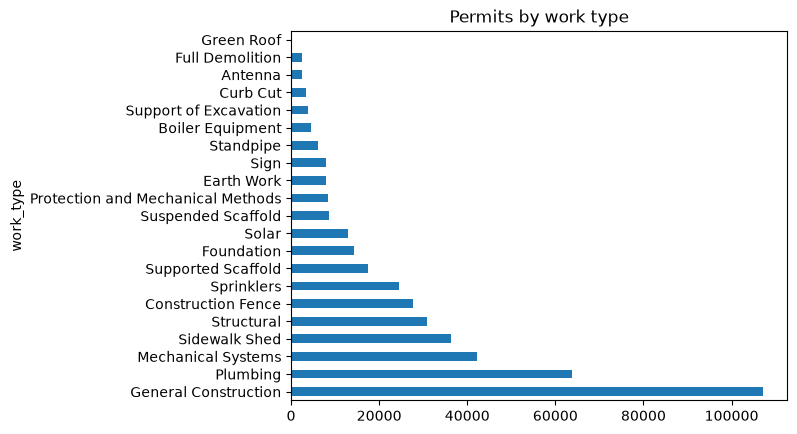

In [11]:
# count permits per work type and draw them as horizontal bars
df_dob["work_type"].value_counts().plot(kind="barh", title="Permits by work type")

<Axes: title={'center': 'Permits by borough'}, xlabel='borough'>

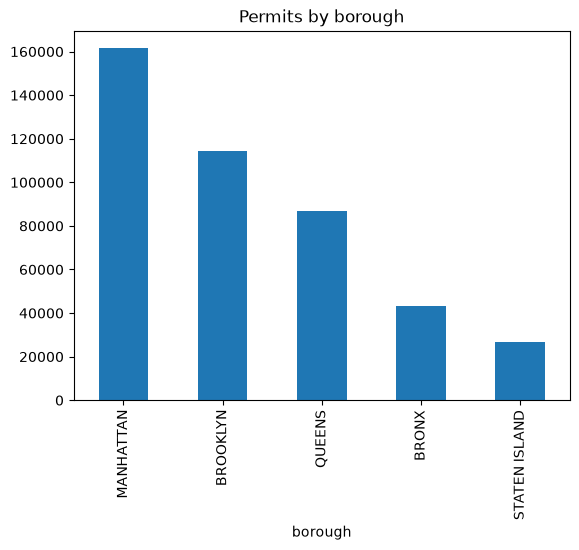

In [12]:
# make borough names upper case (some are mixed case), count them, and draw a bar chart
df_dob["borough"].str.upper().value_counts().plot(kind="bar", title="Permits by borough")

<Axes: title={'center': 'Permits issued per month'}, xlabel='issued_date'>

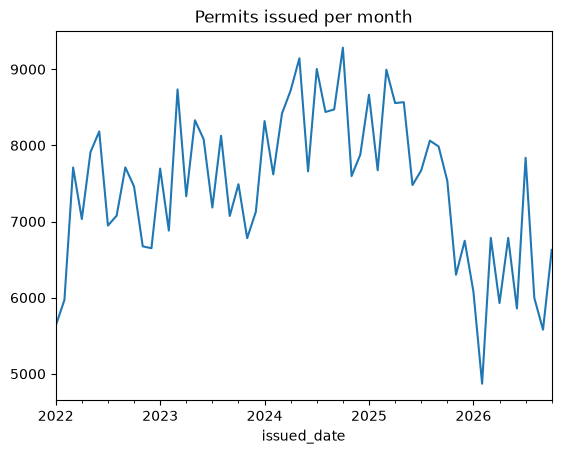

In [13]:
# group issue dates by month, count permits per month, and draw a line over time
df_dob["issued_date"].dt.to_period("M").value_counts().sort_index().plot(title="Permits issued per month")

<Axes: title={'center': 'Estimated job costs'}, ylabel='Frequency'>

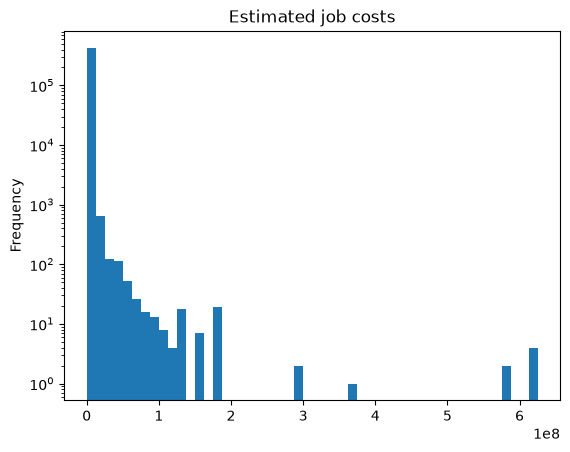

In [14]:
# histogram of job costs; log scale on the y axis because a few huge jobs dwarf the rest
df_dob["estimated_job_costs"].plot(kind="hist", bins=50, logy=True, title="Estimated job costs")

<Axes: title={'center': 'Permit duration (days)'}, ylabel='Frequency'>

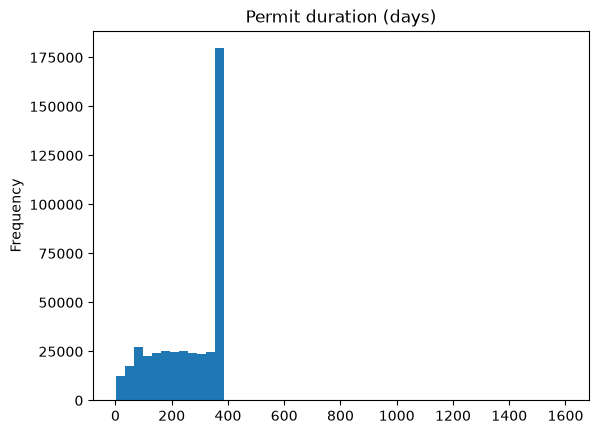

In [15]:
# how many days each permit lasts = expiry date minus issue date
df_dob["duration_days"] = (df_dob["expired_date"] - df_dob["issued_date"]).dt.days
# histogram of durations, only for permits that last more than 0 days
df_dob[df_dob["duration_days"] > 0]["duration_days"].plot(kind="hist", bins=50, title="Permit duration (days)")

## Relations between features

In [16]:
# table: how many permits of each work type in each borough
pd.crosstab(df_dob["borough"].str.upper(), df_dob["work_type"])

work_type,Antenna,Boiler Equipment,Construction Fence,Curb Cut,Earth Work,Foundation,Full Demolition,General Construction,Green Roof,Mechanical Systems,...,Protection and Mechanical Methods,Sidewalk Shed,Sign,Solar,Sprinklers,Standpipe,Structural,Support of Excavation,Supported Scaffold,Suspended Scaffold
borough,,,,,,,,,,,,,,,,,,,,,
BRONX,310,702,4172,357,705,1448,480,8994,1,3331,...,917,5440,648,1580,2145,838,2843,639,1601,1015
BROOKLYN,683,1240,9651,742,1869,4337,766,27255,4,10172,...,2104,9855,1964,2645,5697,1600,8700,1802,5339,1348
MANHATTAN,818,1546,4328,107,316,1112,181,45815,5,18839,...,4296,16320,2975,113,12924,2635,9664,539,8548,5313
QUEENS,557,832,7340,1183,3655,4986,686,19973,1,7715,...,933,4294,1765,6087,3020,933,6742,856,1680,923
STATEN ISLAND,177,113,2276,1056,1382,2489,360,5193,0,2157,...,77,356,508,2566,739,69,2803,120,194,51


<Axes: title={'center': 'Median permit duration by work type'}, ylabel='work_type'>

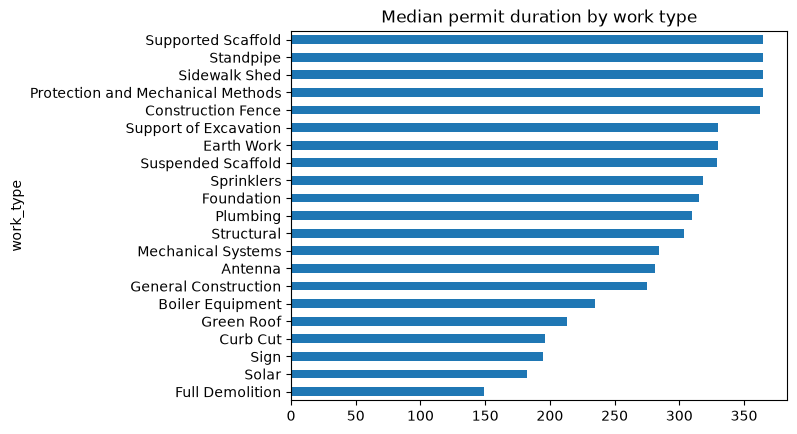

In [17]:
# middle (median) duration for each work type, sorted, as horizontal bars
df_dob.groupby("work_type")["duration_days"].median().sort_values().plot(kind="barh", title="Median permit duration by work type")

<Axes: title={'center': 'Median job cost by work type'}, ylabel='work_type'>

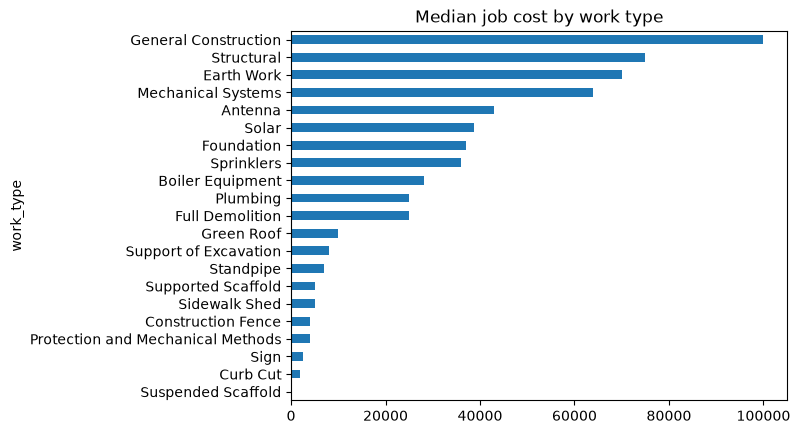

In [18]:
# middle (median) job cost for each work type, sorted, as horizontal bars
df_dob.groupby("work_type")["estimated_job_costs"].median().sort_values().plot(kind="barh", title="Median job cost by work type")

<Axes: title={'center': 'Permit locations'}, xlabel='longitude', ylabel='latitude'>

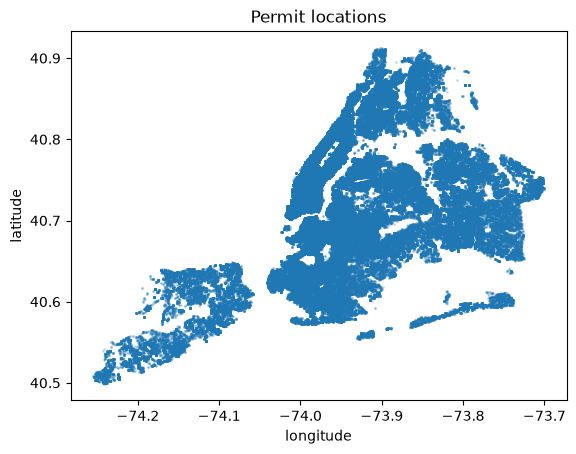

In [19]:
# plot every permit as a tiny dot at its longitude/latitude: a rough map of NYC
df_dob.plot(kind="scatter", x="longitude", y="latitude", s=1, alpha=0.2, title="Permit locations")

In [20]:
# how strongly each pair of number columns moves together (-1 to 1)
df_dob.select_dtypes("number").corr()

,zip_code,c_b_no,latitude,longitude,estimated_job_costs,duration_days
zip_code,1.000000,0.764911,-0.395360,0.507859,-0.007334,-0.022717
c_b_no,0.764911,1.000000,-0.560051,0.171589,-0.009907,-0.034358
latitude,-0.395360,-0.560051,1.000000,0.395809,0.005365,0.015207
longitude,0.507859,0.171589,0.395809,1.000000,-0.002476,-0.011394
estimated_job_costs,-0.007334,-0.009907,0.005365,-0.002476,1.000000,0.006340
duration_days,-0.022717,-0.034358,0.015207,-0.011394,0.006340,1.000000


# Crashes (Motor Vehicle Collisions – Crashes)

In [21]:
# show the first 5 rows so we can see what the data looks like
df_mv.head()

,crash_date,crash_time,borough,zip_code,latitude,longitude,location,on_street_name,off_street_name,cross_street_name,...,contributing_factor_vehicle_2,contributing_factor_vehicle_3,contributing_factor_vehicle_4,contributing_factor_vehicle_5,collision_id,vehicle_type_code1,vehicle_type_code2,vehicle_type_code_3,vehicle_type_code_4,vehicle_type_code_5
0,2026-10-31T00:00:00.000,10:00,MANHATTAN,10027.0,40.810234,-73.952760,"\n, \n(40.810234, -73.95276)",NaN,280 ST NICHOLAS AVE,NaN,...,NaN,NaN,NaN,NaN,dabfc02e02087108a9d291a4ba68a036,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN,NaN
1,2026-10-31T00:00:00.000,10:24,MANHATTAN,NaN,40.838573,-73.933320,"\n, \n(40.838573, -73.93332)",HARLEM RIVER DRIVE,NaN,NaN,...,Does Not Apply,Driver Inattention/Distraction,NaN,NaN,5049d62f6d7951e283a5ff6d76d23f56,Station Wagon/Sport Utility Vehicle,4 dr sedan,Station Wagon/Sport Utility Vehicle,NaN,NaN
2,2026-10-31T00:00:00.000,16:19,QUEENS,11358.0,40.751785,-73.807045,"\n, \n(40.751785, -73.807045)",160 ST,NaN,LABURNUM AVE,...,Driver Inexperience,NaN,NaN,NaN,9e8008eb07fd452f1dac6f29fa217f1a,4 dr sedan,4 dr sedan,NaN,NaN,NaN
3,2026-10-31T00:00:00.000,03:00,QUEENS,NaN,40.689716,-73.776115,"\n, \n(40.689716, -73.776115)",NaN,115-26 173 ST,NaN,...,Backing Unsafely,NaN,NaN,NaN,997bbb4491ed136cc77322c66a500997,4 dr sedan,NaN,NaN,NaN,NaN
4,2026-10-31T00:00:00.000,02:33,BROOKLYN,NaN,40.651210,-73.958920,"\n, \n(40.65121, -73.95892)",MARTENSE ST,NaN,FLATBUSH AVE,...,Does Not Apply,NaN,NaN,NaN,b4017d7f285297caadc18c42986a7837,Station Wagon/Sport Utility Vehicle,4 dr sedan,NaN,NaN,NaN


In [22]:
# list every column name
df_mv.columns.tolist()

['crash_date',
 'crash_time',
 'borough',
 'zip_code',
 'latitude',
 'longitude',
 'location',
 'on_street_name',
 'off_street_name',
 'cross_street_name',
 'number_of_persons_injured',
 'number_of_persons_killed',
 'number_of_pedestrians_injured',
 'number_of_pedestrians_killed',
 'number_of_cyclist_injured',
 'number_of_cyclist_killed',
 'number_of_motorist_injured',
 'number_of_motorist_killed',
 'contributing_factor_vehicle_1',
 'contributing_factor_vehicle_2',
 'contributing_factor_vehicle_3',
 'contributing_factor_vehicle_4',
 'contributing_factor_vehicle_5',
 'collision_id',
 'vehicle_type_code1',
 'vehicle_type_code2',
 'vehicle_type_code_3',
 'vehicle_type_code_4',
 'vehicle_type_code_5']

In [23]:
# column types and how many non-empty values each column has
df_mv.info()

<class 'pandas.DataFrame'>
RangeIndex: 447156 entries, 0 to 447155
Data columns (total 29 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   crash_date                     447156 non-null  str    
 1   crash_time                     447156 non-null  str    
 2   borough                        345885 non-null  str    
 3   zip_code                       321362 non-null  float64
 4   latitude                       422635 non-null  float64
 5   longitude                      422635 non-null  float64
 6   location                       422635 non-null  str    
 7   on_street_name                 317378 non-null  str    
 8   off_street_name                129774 non-null  str    
 9   cross_street_name              230935 non-null  str    
 10  number_of_persons_injured      447156 non-null  int64  
 11  number_of_persons_killed       447156 non-null  int64  
 12  number_of_pedestrians_injured  447156 non

In [24]:
# count the missing values in each column
df_mv.isnull().sum()

crash_date                            0
crash_time                            0
borough                          101271
zip_code                         125794
latitude                          24521
longitude                         24521
location                          24521
on_street_name                   129778
off_street_name                  317382
cross_street_name                216221
number_of_persons_injured             0
number_of_persons_killed              0
number_of_pedestrians_injured         0
number_of_pedestrians_killed          0
number_of_cyclist_injured             0
number_of_cyclist_killed              0
number_of_motorist_injured            0
number_of_motorist_killed             0
contributing_factor_vehicle_1      2820
contributing_factor_vehicle_2    103576
contributing_factor_vehicle_3    407561
contributing_factor_vehicle_4    436786
contributing_factor_vehicle_5    444086
collision_id                          0
vehicle_type_code1                 7354


In [25]:
# basic statistics (mean, min, max, quartiles) for the number columns
df_mv.describe()

,zip_code,latitude,longitude,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_injured,number_of_pedestrians_killed,number_of_cyclist_injured,number_of_cyclist_killed,number_of_motorist_injured,number_of_motorist_killed
count,321362.000000,422635.000000,422635.000000,447156.000000,447156.000000,447156.000000,447156.000000,447156.000000,447156.000000,447156.000000,447156.000000
mean,10879.912824,40.117166,-72.820077,0.562853,0.002809,0.098621,0.001268,0.053652,0.000197,0.381730,0.001076
std,533.467005,4.928412,8.945195,0.849649,0.056044,0.315287,0.036578,0.229403,0.014027,0.827184,0.036278
min,10000.000000,0.000000,-74.254960,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,10454.000000,40.663655,-73.967700,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,11208.000000,40.713460,-73.921524,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,11237.000000,40.771940,-73.864586,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,12345.000000,40.912827,0.000000,40.000000,5.000000,19.000000,4.000000,3.000000,1.000000,40.000000,5.000000


In [26]:
# count rows that are exact copies of another row
df_mv.duplicated().sum()

np.int64(0)

In [27]:
# turn the date text into real dates
df_mv["crash_date"] = pd.to_datetime(df_mv["crash_date"])
# take the hour from the time text, e.g. "14:30" -> 14
df_mv["hour"] = df_mv["crash_time"].str.split(":").str[0].astype(int)

## Single features

<Axes: title={'center': 'Crashes by borough (NaN = missing)'}, xlabel='borough'>

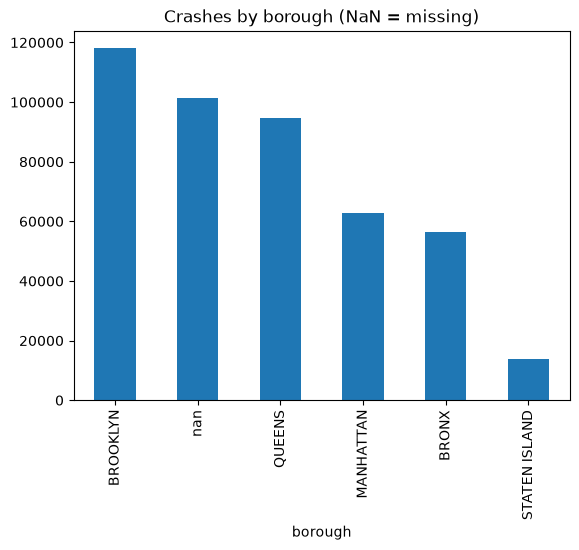

In [28]:
# count crashes per borough, keeping the missing ones (NaN) so we can see how many there are
df_mv["borough"].value_counts(dropna=False).plot(kind="bar", title="Crashes by borough (NaN = missing)")

<Axes: title={'center': 'Crashes per month'}, xlabel='crash_date'>

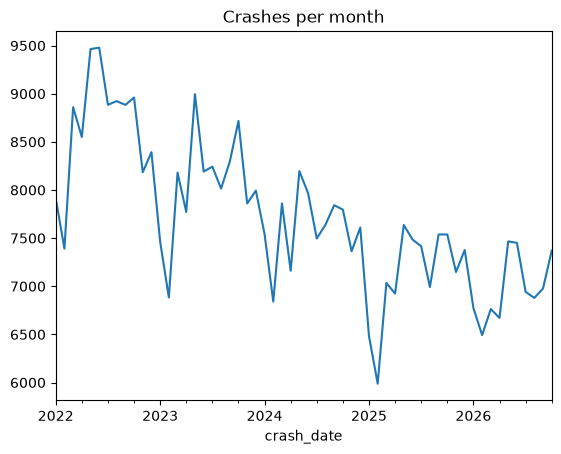

In [29]:
# count crashes per month and draw a line over time
df_mv["crash_date"].dt.to_period("M").value_counts().sort_index().plot(title="Crashes per month")

<Axes: title={'center': 'Crashes by hour'}, xlabel='hour'>

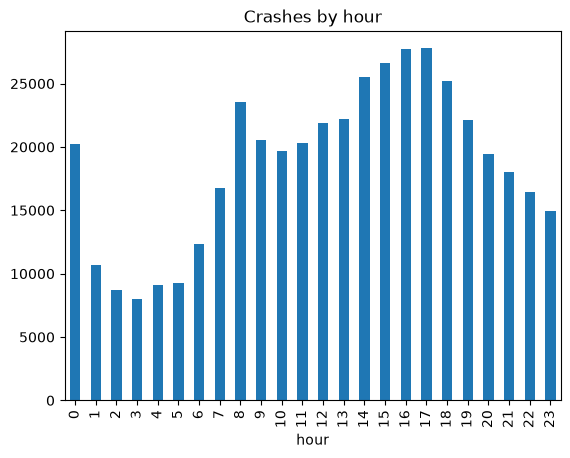

In [30]:
# count crashes for each hour of the day (0 to 23)
df_mv["hour"].value_counts().sort_index().plot(kind="bar", title="Crashes by hour")

<Axes: title={'center': 'Crashes by weekday'}, xlabel='crash_date'>

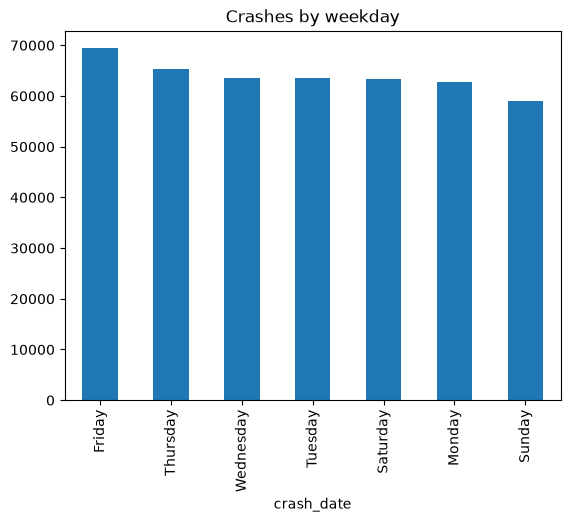

In [31]:
# count crashes for each day of the week
df_mv["crash_date"].dt.day_name().value_counts().plot(kind="bar", title="Crashes by weekday")

<Axes: title={'center': 'Persons injured per crash'}, xlabel='number_of_persons_injured'>

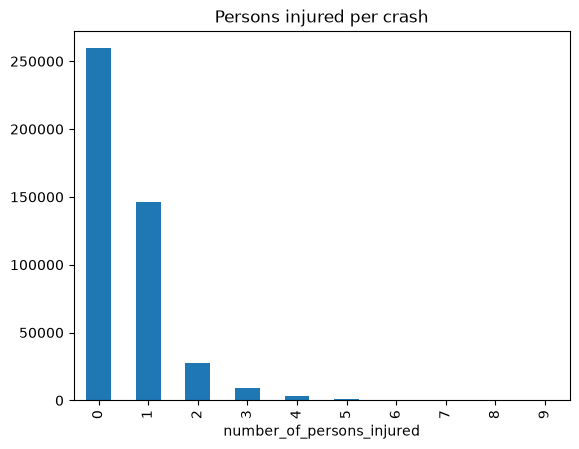

In [32]:
# how many crashes injured 0, 1, 2, ... people (first 10 values)
df_mv["number_of_persons_injured"].value_counts().sort_index().head(10).plot(kind="bar", title="Persons injured per crash")

<Axes: title={'center': 'Top contributing factors'}, ylabel='contributing_factor_vehicle_1'>

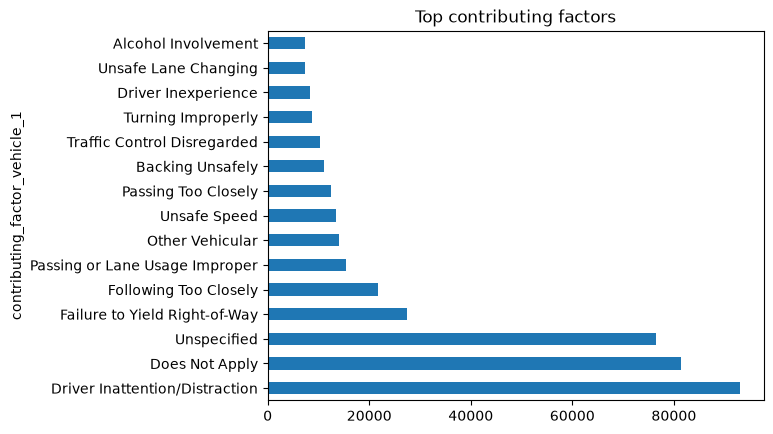

In [33]:
# the 15 most common reasons police gave for crashes
df_mv["contributing_factor_vehicle_1"].value_counts().head(15).plot(kind="barh", title="Top contributing factors")

<Axes: title={'center': 'Top vehicle types (messy labels)'}, ylabel='vehicle_type_code1'>

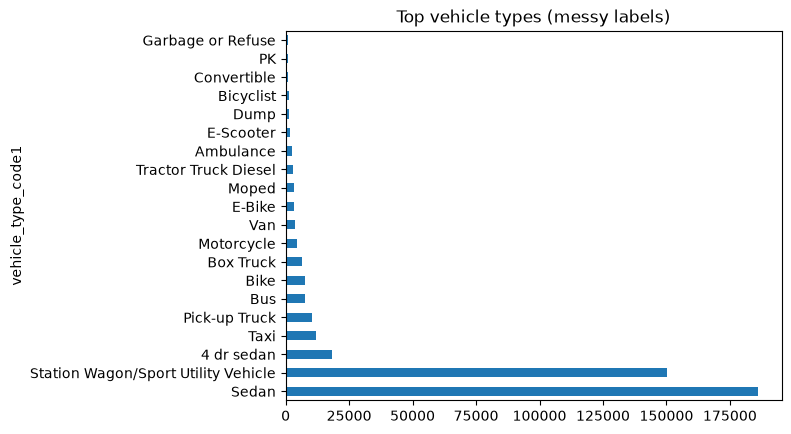

In [34]:
# the 20 most common vehicle labels; this shows how messy the labels are
df_mv["vehicle_type_code1"].value_counts().head(20).plot(kind="barh", title="Top vehicle types (messy labels)")

## Relations between features

<Axes: title={'center': 'Injuries by borough and type'}, xlabel='borough'>

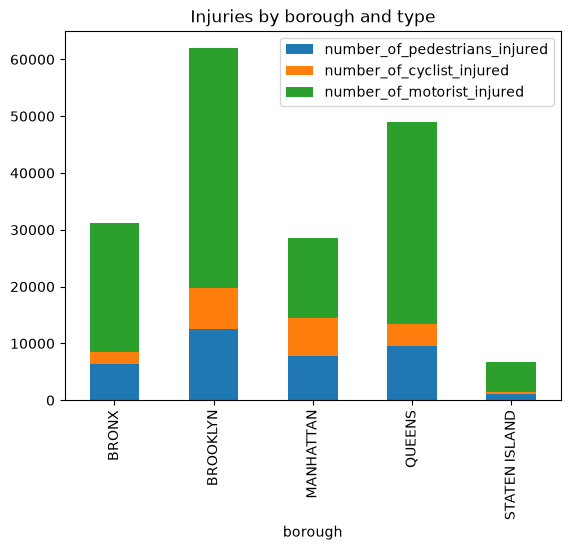

In [35]:
# the three injury columns: pedestrians, cyclists, motorists
injury_cols = ["number_of_pedestrians_injured", "number_of_cyclist_injured", "number_of_motorist_injured"]
# add up injuries per borough and stack the three types in one bar per borough
df_mv.groupby("borough")[injury_cols].sum().plot(kind="bar", stacked=True, title="Injuries by borough and type")

<Axes: title={'center': 'Avg injuries per crash by hour'}, xlabel='hour'>

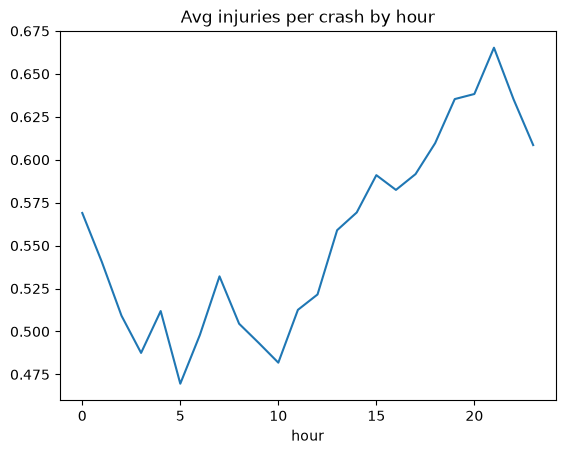

In [36]:
# average people injured per crash for each hour of the day
df_mv.groupby("hour")["number_of_persons_injured"].mean().plot(title="Avg injuries per crash by hour")

<Axes: title={'center': 'Avg injuries by factor'}, ylabel='contributing_factor_vehicle_1'>

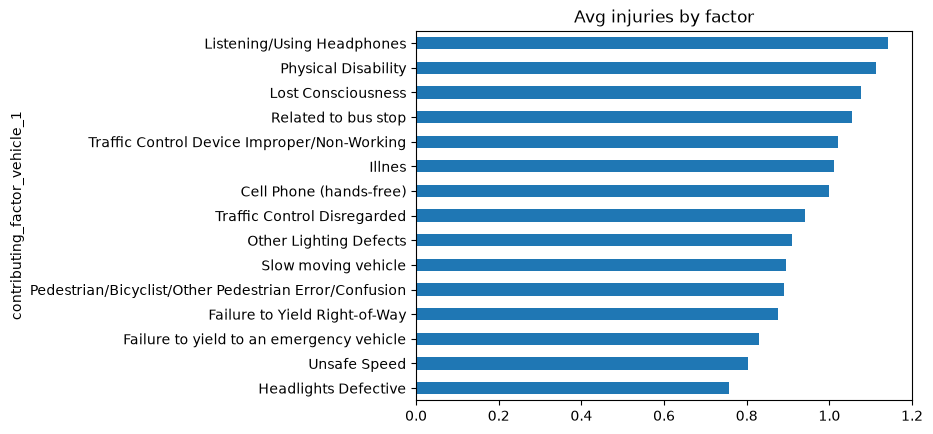

In [37]:
# average people injured per crash for each reason; show the 15 highest
df_mv.groupby("contributing_factor_vehicle_1")["number_of_persons_injured"].mean().sort_values().tail(15).plot(kind="barh", title="Avg injuries by factor")

<Axes: title={'center': 'Crash locations'}, xlabel='longitude', ylabel='latitude'>

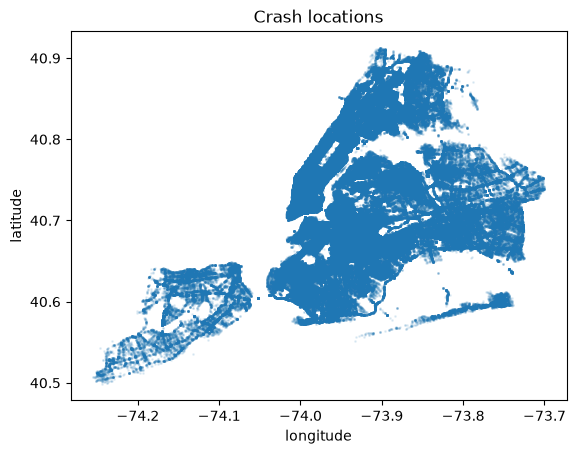

In [38]:
# map of crashes; the filter drops points at 0,0 (bad coordinates) that would squash the map
df_mv[(df_mv["latitude"] > 40) & (df_mv["longitude"] < -73)].plot(kind="scatter", x="longitude", y="latitude", s=1, alpha=0.1, title="Crash locations")

In [39]:
# correlations between number columns, ignoring rows with latitude 0 (bad coordinates)
df_mv[df_mv["latitude"] != 0].select_dtypes("number").corr()

,zip_code,latitude,longitude,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_injured,number_of_pedestrians_killed,number_of_cyclist_injured,number_of_cyclist_killed,number_of_motorist_injured,number_of_motorist_killed,hour
zip_code,1.000000,-0.507980,0.447567,0.022804,-0.002780,-0.019173,-0.002291,-0.058542,-0.001999,0.049110,0.000059,-0.012112
latitude,-0.507980,1.000000,0.340892,-0.003138,0.001254,0.006597,0.000117,0.011782,0.000547,-0.010382,0.000886,-0.008805
longitude,0.447567,0.340892,1.000000,0.034979,-0.000897,-0.011711,-0.000557,-0.055956,-0.002575,0.058690,0.000480,-0.013896
number_of_persons_injured,0.022804,-0.003138,0.034979,1.000000,0.002139,0.215201,-0.003907,0.137533,-0.007675,0.883028,0.013566,0.048869
number_of_persons_killed,-0.002780,0.001254,-0.000897,0.002139,1.000000,-0.001624,0.654773,-0.010662,0.256510,0.006865,0.649962,-0.006606
number_of_pedestrians_injured,-0.019173,0.006597,-0.011711,0.215201,-0.001624,1.000000,0.008810,-0.065017,-0.003404,-0.132117,-0.008102,0.056170
number_of_pedestrians_killed,-0.002291,0.000117,-0.000557,-0.003907,0.654773,0.008810,1.000000,-0.007280,0.003898,-0.004448,0.004083,-0.001033
number_of_cyclist_injured,-0.058542,0.011782,-0.055956,0.137533,-0.010662,-0.065017,-0.007280,1.000000,-0.001897,-0.102916,-0.006931,0.050126
number_of_cyclist_killed,-0.001999,0.000547,-0.002575,-0.007675,0.256510,-0.003404,0.003898,-0.001897,1.000000,-0.005570,-0.000419,0.000428
number_of_motorist_injured,0.049110,-0.010382,0.058690,0.883028,0.006865,-0.132117,-0.004448,-0.102916,-0.005570,1.000000,0.019949,0.008492


# Pre-cleaning
Everything below comes from the EDA outputs above. Mean is never used: every numeric column with gaps is skewed, so we use the median.

**Permits**
| Found in EDA | Fix | Why |
|---|---|---|
| borough mixed case (10 values instead of 5) | `.str.upper()` | standardize |
| 12,122 duplicate rows | drop duplicates | same permit counted twice |
| 35 missing job number, 2,158 missing lat/lon, 628 missing ZIP | drop rows | location can't be guessed and is needed for the ~100 m grid join (<1% of rows) |
| c_b_no missing 4,365 | drop column | not used, ZIP + coords already give location |
| filing_reason missing 154 | fill with mode | categorical |
| job_description missing 17 | fill "Unknown" | free text |
| 30,123 costs = 0 and ~10k at $1 | costs under $100 set to NaN, fill with median of its work type (citywide median if the whole type is 0) | 0 means not reported; a shed costs far less than a building |
| cost very skewed (median 25k, max 625M) | add `log_cost` (log10) | normalize for charts |
| 233 permits expire before issued, 346 last 0 days | drop | impossible active window |
| 449 missing expired_date | fill with median duration of its work type | we need the active window |

**Crashes**
| Found in EDA | Fix | Why |
|---|---|---|
| 0 duplicates | drop duplicate collision_id anyway | safety |
| 6,282 lat/lon = 0, 24,521 missing | set 0 to NaN, drop | can't be placed; caused the fake -0.9998 corr |
| `location` column | drop | copy of lat/lon |
| ZIP 12345 | set to NaN | not an NYC ZIP |
| ZIP missing 28%, borough 23% | fill with the mode ZIP/borough of crashes in the same ~100 m grid cell | neighbours share a ZIP |
| contributing factor 1 missing 2,820 | fill "Unspecified" | the mode would invent a cause |
| "Illnes" typo | fix to "Illness" | standardize |
| vehicle_type_code1: 1,008 labels, 7,354 missing | fill with mode, lowercase, map to ~10 groups | Sedan / 4 dr sedan, Bike / Bicyclist are the same thing |
| factors and vehicles 2-5 mostly empty | leave | blank = no second vehicle |
| street names missing | leave | not used |
| injury counts | nothing | no missing, no negatives |


## Permits

In [40]:
# make all borough names upper case so "Brooklyn" and "BROOKLYN" become one value
df_dob["borough"] = df_dob["borough"].str.upper()
# remove rows that are exact copies
df_dob = df_dob.drop_duplicates()

In [41]:
# drop rows with no job number or no location: we can't place them on the map
df_dob = df_dob.dropna(subset=["job_filing_number", "latitude", "longitude", "zip_code"])
# drop the community board column: we don't use it
df_dob = df_dob.drop(columns=["c_b_no"])

In [42]:
# fill missing filing reasons with the most common reason
df_dob["filing_reason"] = df_dob["filing_reason"].fillna(df_dob["filing_reason"].mode()[0])
# fill missing descriptions with the word "Unknown"
df_dob["job_description"] = df_dob["job_description"].fillna("Unknown")

In [43]:
# costs under $100 are not real costs, so turn them into "missing"
df_dob["estimated_job_costs"] = df_dob["estimated_job_costs"].where(df_dob["estimated_job_costs"] >= 100)  # $0 and $1 are placeholders
# fill missing costs with the median cost of the same work type
df_dob["estimated_job_costs"] = df_dob["estimated_job_costs"].fillna(df_dob.groupby("work_type")["estimated_job_costs"].transform("median"))
# any still missing: fill with the median cost of all permits
df_dob["estimated_job_costs"] = df_dob["estimated_job_costs"].fillna(df_dob["estimated_job_costs"].median())  # Suspended Scaffold has no costs at all
# log10 of cost (1,000 -> 3, 1,000,000 -> 6) so huge costs don't squash the charts
df_dob["log_cost"] = np.log10(df_dob["estimated_job_costs"])

In [44]:
# remove permits that last 0 days or end before they start (impossible); keep missing ones for now
df_dob = df_dob[df_dob["duration_days"].isna() | (df_dob["duration_days"] > 0)]
# fill a missing duration with the median duration of the same work type
df_dob["duration_days"] = df_dob["duration_days"].fillna(df_dob.groupby("work_type")["duration_days"].transform("median"))
# rebuild the expiry date from issue date + duration, so it is filled in too
df_dob["expired_date"] = df_dob["issued_date"] + pd.to_timedelta(df_dob["duration_days"], unit="D")

In [45]:
# ZIP codes are whole numbers, so store them as integers (e.g. 10001.0 -> 10001)
df_dob["zip_code"] = df_dob["zip_code"].astype(int)
# rows and columns left after cleaning
print(df_dob.shape)
# check that nothing is missing any more
df_dob.isnull().sum()

(417908, 15)


job_filing_number      0
work_type              0
filing_reason          0
permit_status          0
borough                0
zip_code               0
latitude               0
longitude              0
approved_date          0
issued_date            0
expired_date           0
estimated_job_costs    0
job_description        0
duration_days          0
log_cost               0
dtype: int64

<Axes: title={'center': 'Permits by borough (cleaned)'}, xlabel='borough'>

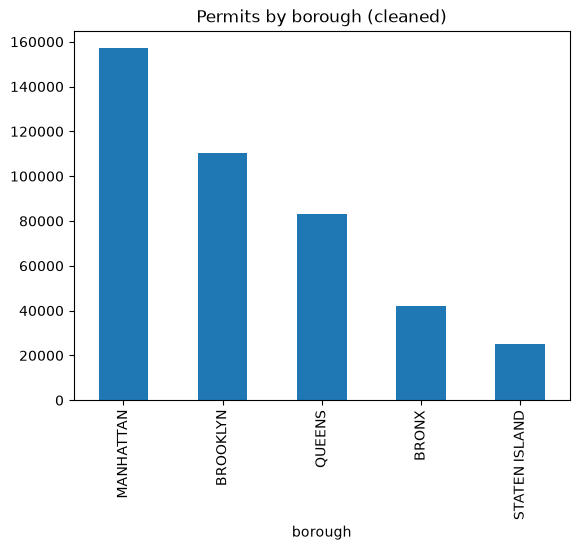

In [46]:
# check: now there should be exactly 5 boroughs
df_dob["borough"].value_counts().plot(kind="bar", title="Permits by borough (cleaned)")

<Axes: title={'center': 'Permit duration in days (cleaned)'}, ylabel='Frequency'>

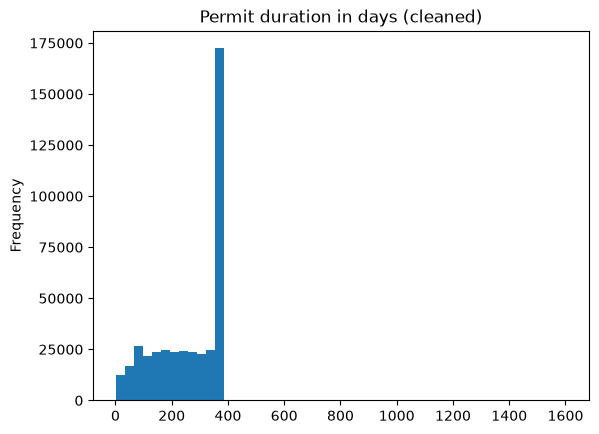

In [47]:
# check: durations after removing impossible ones and filling the gaps
df_dob["duration_days"].plot(kind="hist", bins=50, title="Permit duration in days (cleaned)")

<Axes: title={'center': 'Job cost, log10 (cleaned)'}, ylabel='Frequency'>

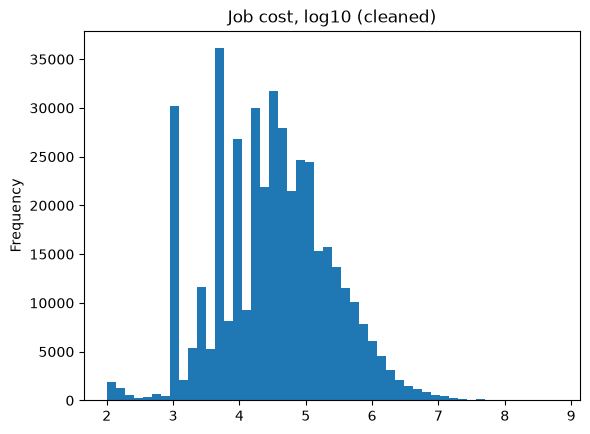

In [48]:
# check: log cost has a much more readable shape than the raw cost
df_dob["log_cost"].plot(kind="hist", bins=50, title="Job cost, log10 (cleaned)")

## Crashes

In [49]:
# keep one row per crash ID (removes duplicates if there are any)
df_mv = df_mv.drop_duplicates(subset="collision_id")
# drop the "location" column: it's just latitude and longitude again
df_mv = df_mv.drop(columns=["location"])

In [50]:
# latitude/longitude of 0 means "unknown" (that's in the ocean), so make them missing
df_mv[["latitude", "longitude"]] = df_mv[["latitude", "longitude"]].replace(0, np.nan)
# drop crashes with no location: we can't place them
df_mv = df_mv.dropna(subset=["latitude", "longitude"])

In [51]:
# NYC ZIPs go up to 11697; anything higher (like 12345) is fake, so make it missing
df_mv["zip_code"] = df_mv["zip_code"].where(df_mv["zip_code"] <= 11697)
# ~100 m square id: round lat and lon to 3 decimals and glue them, e.g. "40.751,-73.987"
df_mv["cell"] = df_mv["latitude"].round(3).astype(str) + "," + df_mv["longitude"].round(3).astype(str)

In [52]:
# for each square, the most common ZIP among crashes that do have a ZIP
zip_mode = df_mv.dropna(subset=["zip_code"]).groupby("cell")["zip_code"].agg(lambda x: x.mode()[0])
# for each square, the most common borough among crashes that do have a borough
boro_mode = df_mv.dropna(subset=["borough"]).groupby("cell")["borough"].agg(lambda x: x.mode()[0])

In [53]:
# fill a missing ZIP with the usual ZIP of that crash's square (neighbours share a ZIP)
df_mv["zip_code"] = df_mv["zip_code"].fillna(df_mv["cell"].map(zip_mode)).astype("Int64")
# fill a missing borough the same way
df_mv["borough"] = df_mv["borough"].fillna(df_mv["cell"].map(boro_mode))

In [54]:
# missing reason -> "Unspecified" (guessing a reason would be made up); also fix the "Illnes" typo
df_mv["contributing_factor_vehicle_1"] = df_mv["contributing_factor_vehicle_1"].fillna("Unspecified").replace("Illnes", "Illness")

In [55]:
# lookup table: each messy vehicle label (left) -> one of about 10 simple groups (right)
# labels that mean the same thing ("sedan", "4 dr sedan") go to the same group ("car")
vehicle_groups = {
    "sedan": "car", "station wagon/sport utility vehicle": "car", "4 dr sedan": "car", "2 dr sedan": "car",
    "convertible": "car", "3-door": "car", "subn": "car", "unknown car": "car", "carry all": "car", "limo": "car", "van": "car",
    "taxi": "taxi",
    "pick-up truck": "truck", "pk": "truck", "box truck": "truck", "tractor truck diesel": "truck", "tractor truck gasoline": "truck",
    "dump": "truck", "garbage or refuse": "truck", "flat bed": "truck", "flat bed truck": "truck", "delivery truck": "truck",
    "tow truck / wrecker": "truck", "tow truck": "truck", "chassis cab": "truck", "tractor trailer": "truck", "tanker": "truck",
    "unknown truck": "truck", "flat rack": "truck", "concrete mixer": "truck", "truck": "truck", "utility": "truck",
    "bus": "bus", "bus (omnibus)": "bus", "school bus": "bus",
    "bike": "bike", "bicyclist": "bike",
    "e-bike": "e-bike", "e-bike (must have pedals)": "e-bike",
    "e-scooter": "scooter/moped", "e-scooter (standing)": "scooter/moped", "standing scooter": "scooter/moped",
    "moped": "scooter/moped", "motorscooter": "scooter/moped", "scooter": "scooter/moped",
    "motorcycle": "motorcycle", "motorbike": "motorcycle", "dirt bike": "motorcycle",
    "ambulance": "emergency", "police vehicle": "emergency", "fire vehicle": "emergency", "fire truck": "emergency",
    "firetruck": "emergency", "fdny ambul": "emergency", "ambu": "emergency",
}

In [56]:
# fill a missing vehicle label with the most common label
df_mv["vehicle_type_code1"] = df_mv["vehicle_type_code1"].fillna(df_mv["vehicle_type_code1"].mode()[0])
# lower-case and trim each label, look up its group; labels not in the table become "other"
df_mv["vehicle"] = df_mv["vehicle_type_code1"].str.lower().str.strip().map(vehicle_groups).fillna("other")

In [57]:
# rows and columns left after cleaning
print(df_mv.shape)
# check that the columns we use have no missing values left
df_mv[["borough", "zip_code", "latitude", "contributing_factor_vehicle_1", "vehicle"]].isnull().sum()

(416353, 31)


borough                           8769
zip_code                         31196
latitude                             0
contributing_factor_vehicle_1        0
vehicle                              0
dtype: int64

<Axes: title={'center': 'Crashes by borough (cleaned)'}, xlabel='borough'>

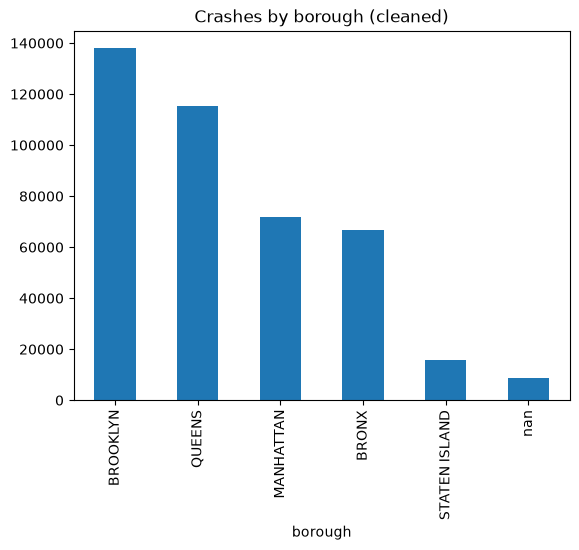

In [58]:
# check: how many crashes still have no borough after filling
df_mv["borough"].value_counts(dropna=False).plot(kind="bar", title="Crashes by borough (cleaned)")

<Axes: title={'center': 'Vehicle groups (cleaned)'}, ylabel='vehicle'>

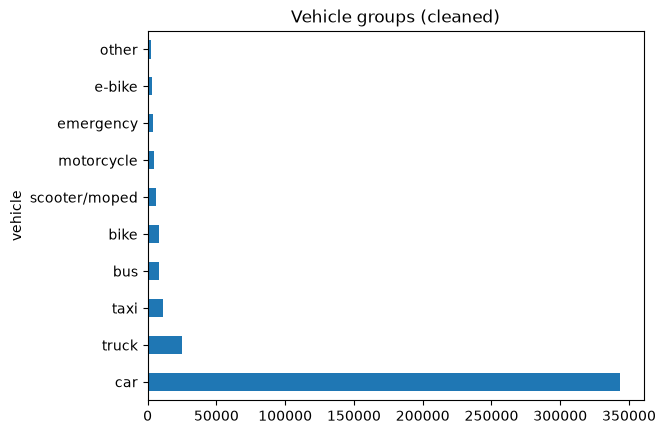

In [59]:
# check: the ~10 clean vehicle groups instead of 1,000+ messy labels
df_mv["vehicle"].value_counts().plot(kind="barh", title="Vehicle groups (cleaned)")

In [60]:
# correlations again after cleaning (the fake one caused by 0 coordinates is gone)
df_mv.select_dtypes("number").corr()

,zip_code,latitude,longitude,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_injured,number_of_pedestrians_killed,number_of_cyclist_injured,number_of_cyclist_killed,number_of_motorist_injured,number_of_motorist_killed,hour
zip_code,1.000000,-0.517961,0.447035,0.025812,-0.002525,-0.020092,-0.001881,-0.057526,-0.001758,0.050886,-0.000515,-0.011985
latitude,-0.517961,1.000000,0.340892,-0.003138,0.001254,0.006597,0.000117,0.011782,0.000547,-0.010382,0.000886,-0.008805
longitude,0.447035,0.340892,1.000000,0.034979,-0.000897,-0.011711,-0.000557,-0.055956,-0.002575,0.058690,0.000480,-0.013896
number_of_persons_injured,0.025812,-0.003138,0.034979,1.000000,0.003861,0.220894,-0.003028,0.139822,-0.007652,0.879000,0.016104,0.050219
number_of_persons_killed,-0.002525,0.001254,-0.000897,0.003861,1.000000,-0.000814,0.673130,-0.010665,0.256060,0.008358,0.625754,-0.005189
number_of_pedestrians_injured,-0.020092,0.006597,-0.011711,0.220894,-0.000814,1.000000,0.009600,-0.066979,-0.003338,-0.132473,-0.008171,0.056613
number_of_pedestrians_killed,-0.001881,0.000117,-0.000557,-0.003028,0.673130,0.009600,1.000000,-0.007508,-0.000479,-0.003823,0.004864,-0.000852
number_of_cyclist_injured,-0.057526,0.011782,-0.055956,0.139822,-0.010665,-0.066979,-0.007508,1.000000,-0.001785,-0.102916,-0.006729,0.050467
number_of_cyclist_killed,-0.001758,0.000547,-0.002575,-0.007652,0.256060,-0.003338,-0.000479,-0.001785,1.000000,-0.005574,-0.000399,0.000632
number_of_motorist_injured,0.050886,-0.010382,0.058690,0.879000,0.008358,-0.132473,-0.003823,-0.102916,-0.005574,1.000000,0.022658,0.008733


## Outliers (IQR check)
The domain-rule outliers are already fixed above: costs under $100 (placeholders), permits that end before they start or last 0 days, crash coordinates of 0, and ZIP 12345. Those values are impossible, so we removed or replaced them.

Now we check the three main number columns with the **IQR rule**:
- **Q1** = the value 25% of the way up the sorted data, **Q3** = the value 75% of the way up.
- **IQR** = Q3 − Q1, the width of the middle half of the data.
- A value is an **outlier** if it is below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR**.

The box plots show the same thing: the box is Q1 to Q3, the line inside is the median, the whiskers stop at the 1.5 × IQR fences, and every dot beyond them is an outlier.

In [61]:
# the three number columns we check, and the table each one comes from
check = {
    'job cost ($)': df_dob['estimated_job_costs'],
    'permit duration (days)': df_dob['duration_days'],
    'people injured per crash': df_mv['number_of_persons_injured'],
}
# we fill this list with one row of results per column
iqr_rows = []
# repeat the same steps for each column
for name, values in check.items():
    # Q1: 25% of values are below it
    low_q = values.quantile(0.25)
    # Q3: 75% of values are below it
    high_q = values.quantile(0.75)
    # IQR: the width of the middle half
    iqr = high_q - low_q
    # fences: anything outside these two numbers is an outlier
    lower_fence = low_q - 1.5 * iqr
    upper_fence = high_q + 1.5 * iqr
    # True for each value outside the fences
    is_outlier = (values < lower_fence) | (values > upper_fence)
    # save the numbers for this column
    iqr_rows.append({'column': name, 'Q1': low_q, 'Q3': high_q, 'IQR': iqr,
                     'lower fence': lower_fence, 'upper fence': upper_fence,
                     'max value': values.max(), 'outliers': is_outlier.sum(),
                     '% outliers': round(is_outlier.mean() * 100, 1)})
# turn the list into a table, one row per column, and round for reading
pd.DataFrame(iqr_rows).set_index('column').round(1)

,Q1,Q3,IQR,lower fence,upper fence,max value,outliers,% outliers
column,,,,,,,,
job cost ($),8000.0,112050.0,104050.0,-148075.0,268125.0,625000000.0,60356,14.4
permit duration (days),165.0,365.0,200.0,-135.0,665.0,1604.0,201,0.0
people injured per crash,0.0,1.0,1.0,-1.5,2.5,34.0,12823,3.1


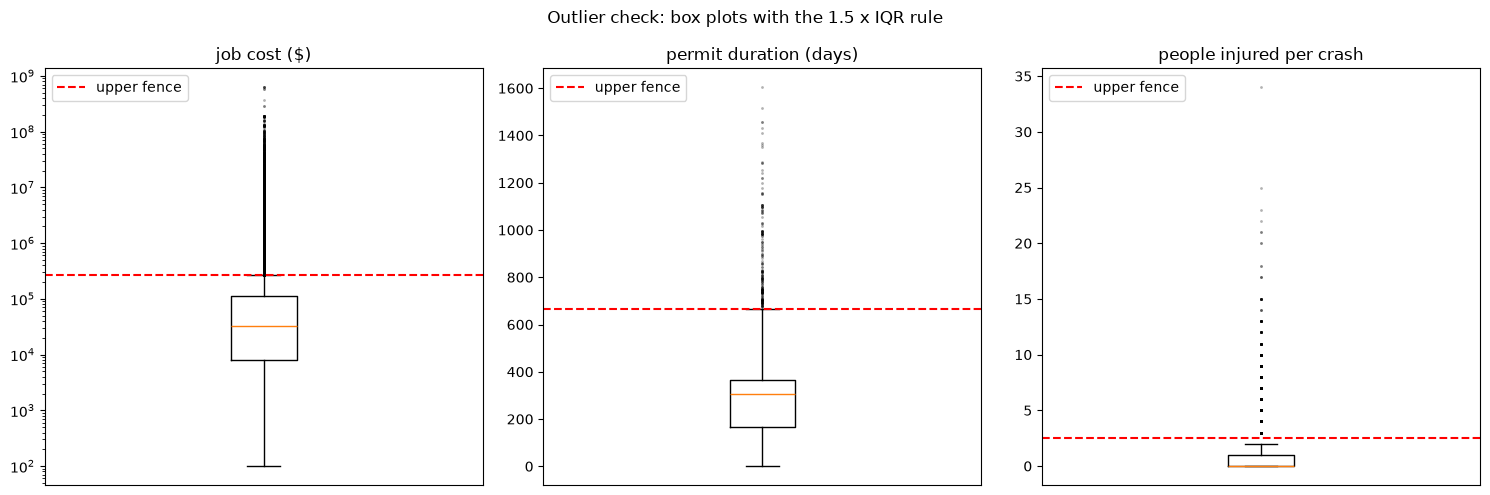

In [62]:
# three charts side by side, one per column
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
# draw a box plot in each chart; whis=1.5 puts the whiskers at the 1.5 x IQR fences
for ax, (name, values) in zip(axes, check.items()):
    ax.boxplot(values, whis=1.5, flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.3})
    # the red dashed line is the upper fence from the table above
    ax.axhline(pd.DataFrame(iqr_rows).set_index('column').loc[name, 'upper fence'], color='red', linestyle='--', label='upper fence')
    # chart title, and no x tick label (only one box per chart)
    ax.set_title(name)
    ax.set_xticks([])
    # small legend for the red line
    ax.legend(loc='upper left')
# cost goes from $100 to hundreds of millions, so use a log scale to see the box at all
axes[0].set_yscale('log')
# overall title above the three charts
fig.suptitle('Outlier check: box plots with the 1.5 x IQR rule')
# leave room so the titles don't overlap
plt.tight_layout()
# draw the charts
plt.show()

**What the IQR check found, and what we did:**

| Column | Upper fence | Max | Outliers | Keep or drop? | Why |
|---|---|---|---|---|---|
| job cost ($) | $268,125 | $625,000,000 | 60,356 (14.4%) | **keep** | Big jobs (new towers, full demolitions) really do cost millions. 14% of all permits is far too many to be typos, so the data is just very skewed. We never use the mean cost: we use the median and `log_cost`, so these values can't distort the results. |
| permit duration (days) | 665 | 1,604 | 201 (0.05%) | **keep** | Long permits are real, mostly sidewalk sheds renewed again and again. They are exactly what Q4 and Q5 are about, so dropping them would hide the finding. |
| people injured per crash | 2.5 | 34 | 12,823 (3.1%) | **keep** | A crash that injures many people (e.g. a bus crash) is real and is the most serious kind. Dropping them would make streets look safer than they are. We use totals and shares, which handle them fine. |

**Rule we followed:** remove values that are *impossible* (the domain rules above), keep values that are *extreme but real* (the IQR outliers). The lower fences are all below 0, so there are no low outliers.

## Integration: crashes x street permits (same ~100 m grid cell)
- **Issue:** need crashes near active construction.
- **Fix:** give permits the same `cell` as crashes (lat/lon rounded to 3 dp), merge on `cell`.
- **Why:** one simple merge, no distance math.
- **Trade-off:** a crash at the edge of a cell misses a permit just across the line.

In [63]:
# work types that happen on or next to the street (these can affect traffic)
street = ['Sidewalk Shed', 'Supported Scaffold', 'Suspended Scaffold', 'Construction Fence',
          'Full Demolition', 'Earth Work', 'Foundation', 'General Construction']
# keep only those permits; .copy() makes a separate table we can change safely
dob = df_dob[df_dob['work_type'].isin(street)].copy()
# give every permit an id number (its row number)
dob['permit_id'] = dob.index
# how many street-work permits we have
print(len(dob))

213583


In [64]:
# same ~100 m square id as the crashes, so the two tables can be joined on it
dob['cell'] = dob['latitude'].round(3).astype(str) + ',' + dob['longitude'].round(3).astype(str)
# look at a few square ids
dob['cell'].head()

0    40.734,-73.991
1    40.719,-73.987
3    40.903,-73.901
4    40.656,-73.745
7    40.706,-73.799
Name: cell, dtype: str

In [65]:
# THE JOIN: pair every crash with every permit in the same square (inner join on "cell")
pairs = df_mv[['collision_id', 'crash_date', 'cell']].merge(dob[['permit_id', 'work_type', 'issued_date', 'expired_date', 'cell']], on='cell')
# how many crash-permit pairs we got
print(len(pairs))

2432021


In [66]:
# start by labelling every pair "during" the permit
pairs['when'] = 'during'
# crash happened before the permit was issued -> "before"
pairs.loc[pairs['crash_date'] < pairs['issued_date'], 'when'] = 'before'
# crash happened after the permit expired -> "after"
pairs.loc[pairs['crash_date'] > pairs['expired_date'], 'when'] = 'after'

In [67]:
# how many pairs are before, during and after
pairs['when'].value_counts()

when
before    1244713
after      838782
during     348526
Name: count, dtype: int64

## Checks on the merged table

In [68]:
# column types of the joined table (dates must still be dates)
pairs.info()

<class 'pandas.DataFrame'>
RangeIndex: 2432021 entries, 0 to 2432020
Data columns (total 8 columns):
 #   Column        Dtype         
---  ------        -----         
 0   collision_id  str           
 1   crash_date    datetime64[us]
 2   cell          str           
 3   permit_id     int64         
 4   work_type     str           
 5   issued_date   datetime64[us]
 6   expired_date  datetime64[ns]
 7   when          str           
dtypes: datetime64[ns](1), datetime64[us](2), int64(1), str(4)
memory usage: 309.6 MB


In [69]:
# did the join create any missing values?
pairs.isna().sum()

collision_id    0
crash_date      0
cell            0
permit_id       0
work_type       0
issued_date     0
expired_date    0
when            0
dtype: int64

In [70]:
# is the same crash paired with the same permit twice?
pairs.duplicated(['collision_id', 'permit_id']).sum()

np.int64(0)

In [71]:
# any permit that ends before it starts?
(pairs['expired_date'] < pairs['issued_date']).sum()

np.int64(0)

In [72]:
# time span of the crashes
print(df_mv['crash_date'].min(), df_mv['crash_date'].max())
# time span of permit issue dates
print(dob['issued_date'].min(), dob['issued_date'].max())
# time span of permit expiry dates (some go past the last crash date)
print(dob['expired_date'].min(), dob['expired_date'].max())

2022-01-01 00:00:00 2026-10-31 00:00:00
2022-01-01 00:00:00 2026-10-15 00:00:00
2022-01-06 00:00:00 2027-10-15 00:00:00


In [73]:
# how many different crashes found at least one permit, out of all crashes
print(pairs['collision_id'].nunique(), len(df_mv))
# how many different permits found at least one crash, out of all permits
print(pairs['permit_id'].nunique(), len(dob))

253508 416353
189908 213583


In [74]:
# how many permits each crash got paired with (min, average, max ...)
pairs.groupby('collision_id').size().describe()

count    253508.000000
mean          9.593468
std          12.879564
min           1.000000
25%           2.000000
50%           5.000000
75%          12.000000
max         194.000000
dtype: float64

In [75]:
# the 10 squares with the most pairs (the busiest places)
pairs.groupby('cell').size().sort_values().tail(10)

cell
40.762,-73.963     4214
40.766,-73.98      4608
40.748,-73.985     5723
40.761,-73.964     5724
40.764,-73.971     6201
40.755,-73.984     6300
40.725,-73.997     6384
40.756,-74.002     6396
40.755,-73.999     6636
40.757,-73.986    10670
dtype: int64

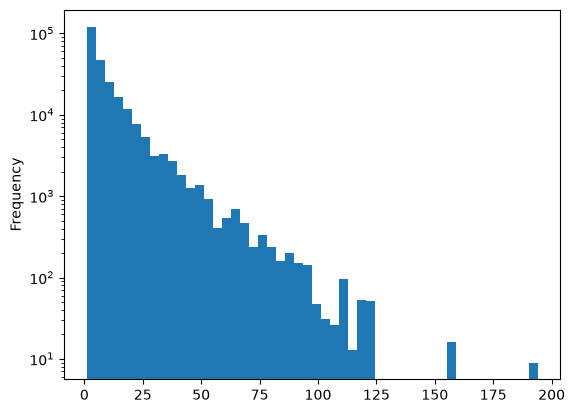

In [76]:
# histogram: how many permits each crash is paired with (log scale, most are small)
pairs.groupby('collision_id').size().plot.hist(bins=50, log=True)
# draw the chart
plt.show()

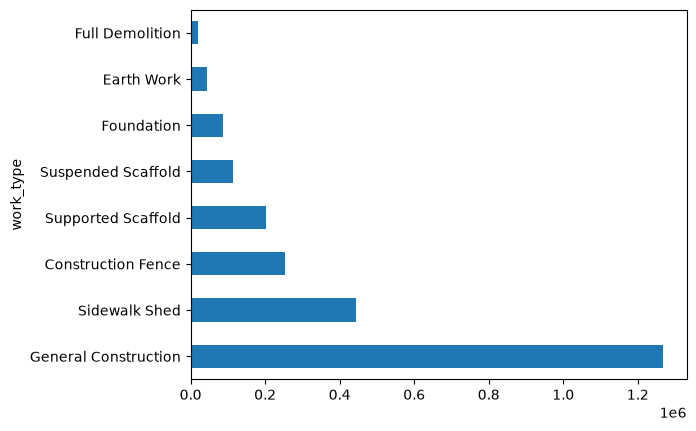

In [77]:
# how many pairs per work type
pairs['work_type'].value_counts().plot.barh()
# draw the chart
plt.show()

In [78]:
# crashes that got more than one label (e.g. "before" one permit and "during" another)
(pairs.groupby('collision_id')['when'].nunique() > 1).sum()

np.int64(134931)

In [79]:
# why each permit was filed (Initial vs Renewal)
dob['filing_reason'].value_counts()

filing_reason
Initial Permit                    131466
Renewal Permit Without Changes     64006
Renewal Permit with Changes        16603
No Work Permit                      1508
Name: count, dtype: int64

In [80]:
# how many permits share a job number with another permit (renewals of the same job)
dob['job_filing_number'].duplicated().sum()

np.int64(69559)

## Post-merge cleaning
| Found | Fix | Why |
|---|---|---|
| 0 missing, 0 duplicate pairs, 0 permits ending before they start | nothing | the pre-cleaning already handled it |
| 69,559 permits are renewals of the same job (same job number) | combine each job into one row: first issue date, last expiry date | otherwise a renewal's "before" is really "during" the first permit |
| 134,931 crashes are "before" one permit and "during" another in the same cell | label each crash once: during if any permit in its cell is active | otherwise one crash is counted on both sides |
| one crash matches up to 194 permits; the busiest Midtown cell has 10,670 pairs | count crashes, not pairs | busy cells would outweigh the rest of the city |
| before/after windows are years long, during is months | compare crashes per cell per month, active vs not active | raw counts are unfair |
| data is 2022-01 to 2026-10, but some permits expire in 2027 | clip expiry at 2026-10-31 | there are no crashes after that date |
| expired_date is ns, others are us | leave | comparisons still work |

## Post-merge fixes: one table of square x month

In [81]:
# merge renewals: one row per job, from its first issue date to its last expiry date
jobs = dob.groupby(['job_filing_number', 'work_type', 'cell'], as_index=False).agg(issued_date=('issued_date', 'min'), expired_date=('expired_date', 'max'))
# permits before, jobs after
print(len(dob), len(jobs))

213583 155144


In [82]:
# our crash data ends in Oct 2026, so cut any job end date after that
jobs['expired_date'] = jobs['expired_date'].clip(upper=pd.Timestamp('2026-10-31'))

In [83]:
# for each job, the list of months it was running
jobs['month'] = [pd.period_range(a, b, freq='M') for a, b in zip(jobs['issued_date'], jobs['expired_date'])]
# one row per (square, month) with work running; explode turns each list into separate rows
active = jobs.explode('month')[['cell', 'month']].drop_duplicates()
# mark these square-months as active
active['active'] = True

In [84]:
# the month of each crash
df_mv['month'] = df_mv['crash_date'].dt.to_period('M')
# count crashes in each (square, month)
crashes = df_mv.groupby(['cell', 'month']).size().reset_index(name='crashes')

In [85]:
# every month from Jan 2022 to Oct 2026
months = pd.period_range('2022-01', '2026-10', freq='M')
# every combination of (square that ever had work) x (month): the full grid
grid = pd.MultiIndex.from_product([jobs['cell'].unique(), months], names=['cell', 'month']).to_frame(index=False)
# left-join crash counts and the active flag onto the grid (squares/months with none stay empty)
grid = grid.merge(crashes, on=['cell', 'month'], how='left').merge(active, on=['cell', 'month'], how='left')
# empty crash count means 0 crashes that month
grid['crashes'] = grid['crashes'].fillna(0)
# empty active means no work that month -> False
grid['active'] = grid['active'].notna()

In [86]:
# number of square-months and total crashes in the grid
print(len(grid), grid['crashes'].sum())
# check: no missing values left after the joins
grid.isna().sum()

1680086 253508.0


cell       0
month      0
crashes    0
active     0
dtype: int64

In [87]:
# average crashes per square-month, with work vs without work
grid.groupby('active')['crashes'].mean()

active
False    0.132450
True     0.175357
Name: crashes, dtype: float64

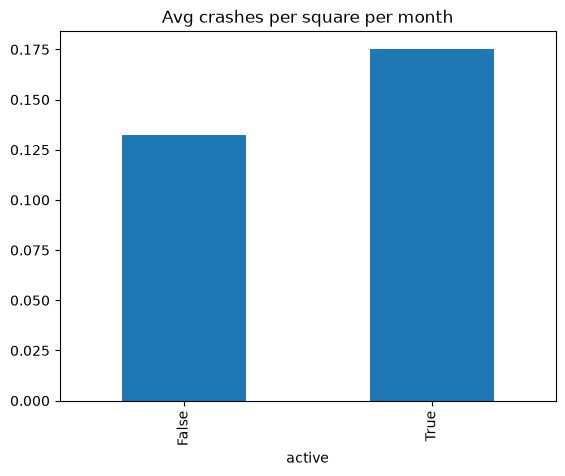

In [88]:
# the same two averages as a bar chart
grid.groupby('active')['crashes'].mean().plot.bar(title='Avg crashes per square per month')
# draw the chart
plt.show()

In [89]:
# for each square: its average crashes in work months (True) and no-work months (False)
per_cell = grid.groupby(['cell', 'active'])['crashes'].mean().unstack()
# work-month average minus no-work-month average, per square
diff = per_cell[True] - per_cell[False]
# share of squares where work months are higher, lower, equal, or can't be compared
print((diff > 0).mean(), (diff < 0).mean(), (diff == 0).mean(), diff.isna().mean())

0.3789484585908102 0.4334242413781199 0.16622363379017502 0.021403666240894813


# Research questions
Rule for every question: use rates or shares, not raw counts (raw counts just show busy places). Say "linked with", not "causes".

| # | Question | Chart | Why this chart (Lecture 4) |
|---|---|---|---|
| Q1 | Do squares with lots of street work already have more crashes in months **without** work? | Scatter | 2 numeric variables |
| Q2 | Comparing a square with itself, how different are its work months from its no-work months? | Histogram | distribution of 1 continuous variable |
| Q3 | Which work type changes crashes most within the same square? | Bar | 1 categorical variable (7 types) |
| Q4 | How long does each work type really last? | Box plot | spread, median, outliers per group |
| Q5 | Which ZIPs have the most "permanent" sidewalk sheds (still up, > 2 years)? | Horizontal bar | ranking with long labels |
| Q6 | Near work, are the injured more often pedestrians or cyclists? | 100% stacked bar | composition |
| Q7 | Which contributing factors become more common near work? | Horizontal bar | ranking with long labels |
| Q8 | Do crashes near work peak during working hours? | Line (2 lines) | change over the 24 hours |
| Q9 | Are trucks a bigger share of crashes near work, in every borough? | Grouped bar | sub-categories (borough × work) |
| Q10 | Did Manhattan crashes drop after congestion pricing (5 Jan 2025) vs other boroughs? | Line (2 lines) | change over time |

## Q1: Do squares with lots of street work already have more crashes, even in months with no work?
- **Why ask:** the +32% above compares busy squares with quiet ones. If busy squares are dangerous anyway, the +32% is about the place, not the work.
- **Data:** per square, x = share of its 58 months with work, y = average crashes in its no-work months.
- **Chart:** scatter. Lecture 4: two numeric variables → scatter.

In [90]:
# per square: share of its months with work (x) and its average crashes in no-work months (y)
q1 = pd.DataFrame({'work_share': grid.groupby('cell')['active'].mean(), 'no_work_crashes': per_cell[False]}).dropna()
# correlation between the two
q1.corr()

,work_share,no_work_crashes
work_share,1.000000,0.133574
no_work_crashes,0.133574,1.000000


In [91]:
# put squares into 4 groups by work share, then average crashes in no-work months per group
q1.groupby(pd.cut(q1['work_share'], [0, 0.25, 0.5, 0.75, 1]))['no_work_crashes'].mean()

work_share
(0.0, 0.25]    0.116467
(0.25, 0.5]    0.139644
(0.5, 0.75]    0.173824
(0.75, 1.0]    0.212563
Name: no_work_crashes, dtype: float64

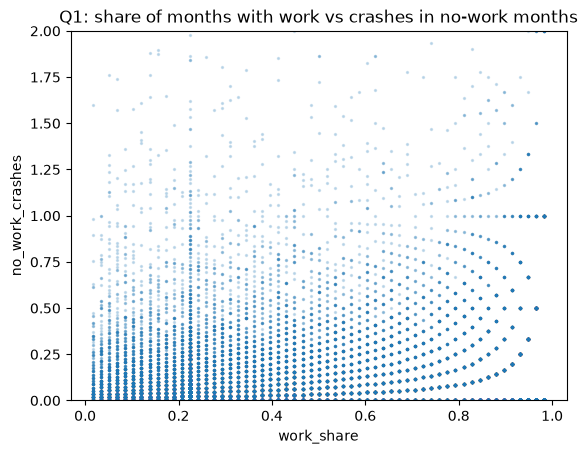

In [92]:
# scatter plot: one dot per square; y axis cut at 2 so the dense part is visible
q1.plot.scatter(x='work_share', y='no_work_crashes', s=2, alpha=0.2, ylim=(0, 2), title='Q1: share of months with work vs crashes in no-work months')
# draw the chart
plt.show()

**What we found (Q1):** the correlation is weak (0.13), but the averages by group are clear. Squares with work in ≤ 25% of their months average **0.116** crashes in their quiet months; squares with work in > 75% of their months average **0.213**, almost double, even when no work is running. So the places that get a lot of street work were already more crash-prone. The +32% from the bar chart above is mostly about the **place**, not the work. (y-axis cut at 2 so the dense part is visible; only a few squares are above it.)

## Q2: Comparing a square with itself, how different are its work months from its no-work months?
- **Why ask:** comparing a square with itself removes the "busy place" effect from Q1.
- **Data:** per square, average crashes in work months − average in no-work months. Only squares with at least 6 months of each, so one month can't swing the result.
- **Chart:** histogram. Lecture 4: one continuous variable → histogram shows its distribution and skew.

In [93]:
# per square: how many work months and how many no-work months it has
n_months = grid.groupby(['cell', 'active']).size().unstack()
# keep only squares with at least 6 months of each, so one month can't swing the result
fair = diff[(n_months[True] >= 6) & (n_months[False] >= 6)]
# how many squares, and the average and median difference
print(len(fair), fair.mean(), fair.median())
# share of squares higher, lower, equal, and with a big difference (more than 1 crash)
print((fair > 0).mean(), (fair < 0).mean(), (fair == 0).mean(), (fair.abs() > 1).mean())

23694 -0.0025946854681469875 0.0
0.38435890942854734 0.4422638642694353 0.17337722630201738 0.000844095551616443


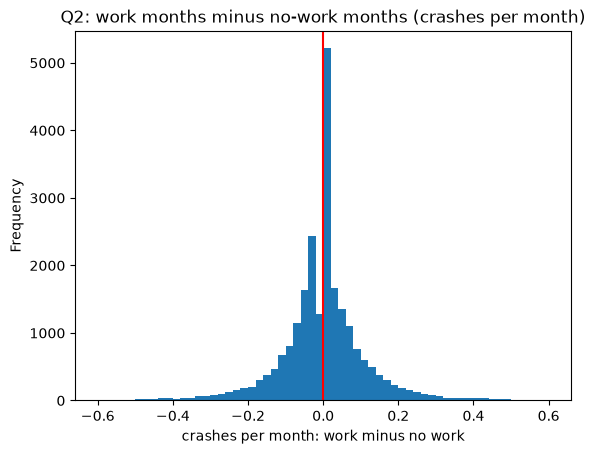

In [94]:
# histogram of the differences, zoomed to -0.6..0.6
fair.plot.hist(bins=60, range=(-0.6, 0.6), title='Q2: work months minus no-work months (crashes per month)')
# label the x axis
plt.xlabel('crashes per month: work minus no work')
# red line at 0 = no difference
plt.axvline(0, color='red')
# draw the chart
plt.show()

**What we found (Q2):** 23,694 squares have at least 6 work months and 6 no-work months. The average difference is **−0.003** crashes per month and the median is **0**. Work months are higher in **38%** of squares, lower in **44%**, equal in **17%**. The histogram is centred on 0 and almost symmetric. So when a square is compared with itself, street work is **not linked with** a clear rise in crashes. (x-axis cut at ±0.6; under 0.1% of squares fall outside ±1.)

## Q3: Which work type changes crashes the most within the same square?
- **Why ask:** Q2 mixes all work types. A demolition or earth work site may change the street more than a shed.
- **Data:** each square gets its most common work type; average the Q2 difference (work − no-work, same square) per type.
- **Chart:** bar. Lecture 4: one categorical variable (7 work types) → bar.

In [95]:
# each square's most common work type
cell_type = jobs.groupby('cell')['work_type'].agg(lambda x: x.mode()[0])
# average difference (from Q2) and number of squares, per work type
q3 = fair.groupby(cell_type).agg(['mean', 'count'])
# show the table
q3

,mean,count
work_type,,
Construction Fence,-0.002868,4881
Earth Work,-0.002727,539
Foundation,-0.001991,743
Full Demolition,0.000143,216
General Construction,-0.002380,15128
Sidewalk Shed,-0.002776,1763
Supported Scaffold,-0.003876,235
Suspended Scaffold,-0.014612,189


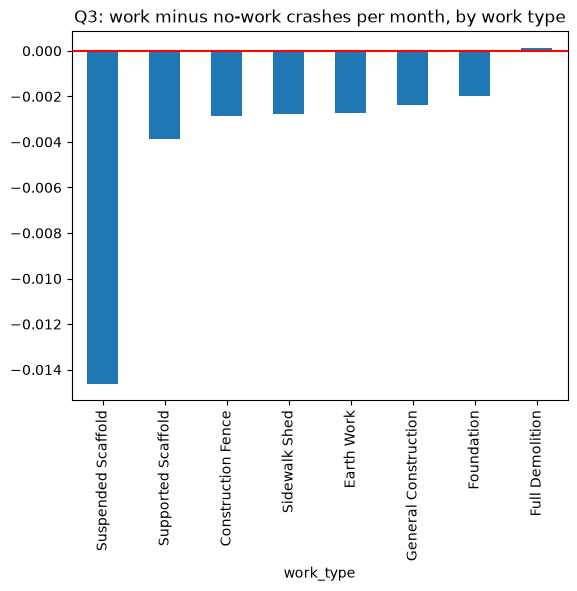

In [96]:
# bar per work type: average work-minus-no-work difference
q3['mean'].sort_values().plot.bar(title='Q3: work minus no-work crashes per month, by work type')
# red line at 0 = no difference
plt.axhline(0, color='red')
# draw the chart
plt.show()

**What we found (Q3):** no work type stands out. Every type's average difference is within 0.015 crashes per month of 0, and most are about −0.003. Full Demolition is closest to 0 (+0.0001); Suspended Scaffold is the most negative (−0.015) but has only 189 squares. Within the same square, no kind of street work is linked with a clear rise in the number of crashes.

## Q4: Do longer jobs come with more crashes per month in their square?
- **Why ask:** a job that stays for years takes space from the street for years. If long jobs also make their square more dangerous every month, the harm adds up.
- **Data:** for each job, crashes in its ~100 m square during the months it was running, divided by the number of months it ran. Jobs are grouped into 5 length bands; the 8 work types are grouped into 4 families.
- **Chart:** scatter of the band averages, joined by lines. Lecture 4 chart chooser: relationship between two variables (job length, crash rate) → scatter. Plotting all 155k jobs would be one blob, so each point is a length band. The 8 work types are grouped into 4 families because the lecture says to keep to 4–5 lines.

In [ ]:
# job length in days = last expiry minus first issue (renewals already merged)
jobs['days'] = (jobs['expired_date'] - jobs['issued_date']).dt.days
# one row per job and month it was running (jobs['month'] is the list of its months); keep the job's row number
job_months = jobs[['cell', 'month']].explode('month').reset_index()
# crashes in the job's square that month (grid already has 0 for months with no crash)
job_months = job_months.merge(grid[['cell', 'month', 'crashes']], on=['cell', 'month'], how='left')
# injured people in the job's square that month: pedestrians and everyone (used again in Q10)
injured = near.groupby(['cell', 'month'])[injury_cols].sum()
injured = pd.DataFrame({'ped_injured': injured[injury_cols[0]], 'injured': injured.sum(axis=1)}).reset_index()
job_months = job_months.merge(injured, on=['cell', 'month'], how='left').fillna({'ped_injured': 0, 'injured': 0})
# per job: totals over the months it ran, and how many months that was
per_job = job_months.groupby('index').agg(crashes_in_square=('crashes', 'sum'), job_months=('month', 'size'),
                                          ped_injured=('ped_injured', 'sum'), injured=('injured', 'sum'))
# attach the totals back to each job (same row numbers)
jobs = jobs.join(per_job)
# check: every job got a value, and the overall crash rate
print(jobs['job_months'].isna().sum(), round(jobs['crashes_in_square'].sum() / jobs['job_months'].sum(), 3))

0 0.196


In [ ]:
# length bands: under 3 months ... over 2 years
length_band = pd.cut(jobs['days'], [0, 90, 180, 365, 730, 10000],
                     labels=['< 3 months', '3–6 months', '6–12 months', '1–2 years', '> 2 years'])
# 8 work types -> 4 families, so the chart has 4 lines (lecture 4: at most 4–5 lines)
family = jobs['work_type'].map({
    'Sidewalk Shed': 'Sheds & scaffolds', 'Supported Scaffold': 'Sheds & scaffolds', 'Suspended Scaffold': 'Sheds & scaffolds',
    'Construction Fence': 'Fences', 'General Construction': 'Building & demolition', 'Full Demolition': 'Building & demolition',
    'Earth Work': 'Ground work', 'Foundation': 'Ground work'})
# crashes per month for each family and band = all crashes / all job months (long jobs count for more months)
totals = jobs.groupby([length_band, family], observed=True)[['crashes_in_square', 'job_months']].sum()
q4 = (totals['crashes_in_square'] / totals['job_months']).unstack()
# show the table: rows = length band, columns = family
q4.round(3)

work_type,Building & demolition,Fences,Ground work,Sheds & scaffolds
days,,,,
< 3 months,0.205,0.144,0.095,0.220
3–6 months,0.213,0.159,0.109,0.219
6–12 months,0.214,0.164,0.109,0.219
1–2 years,0.204,0.157,0.111,0.224
> 2 years,0.185,0.158,0.120,0.218


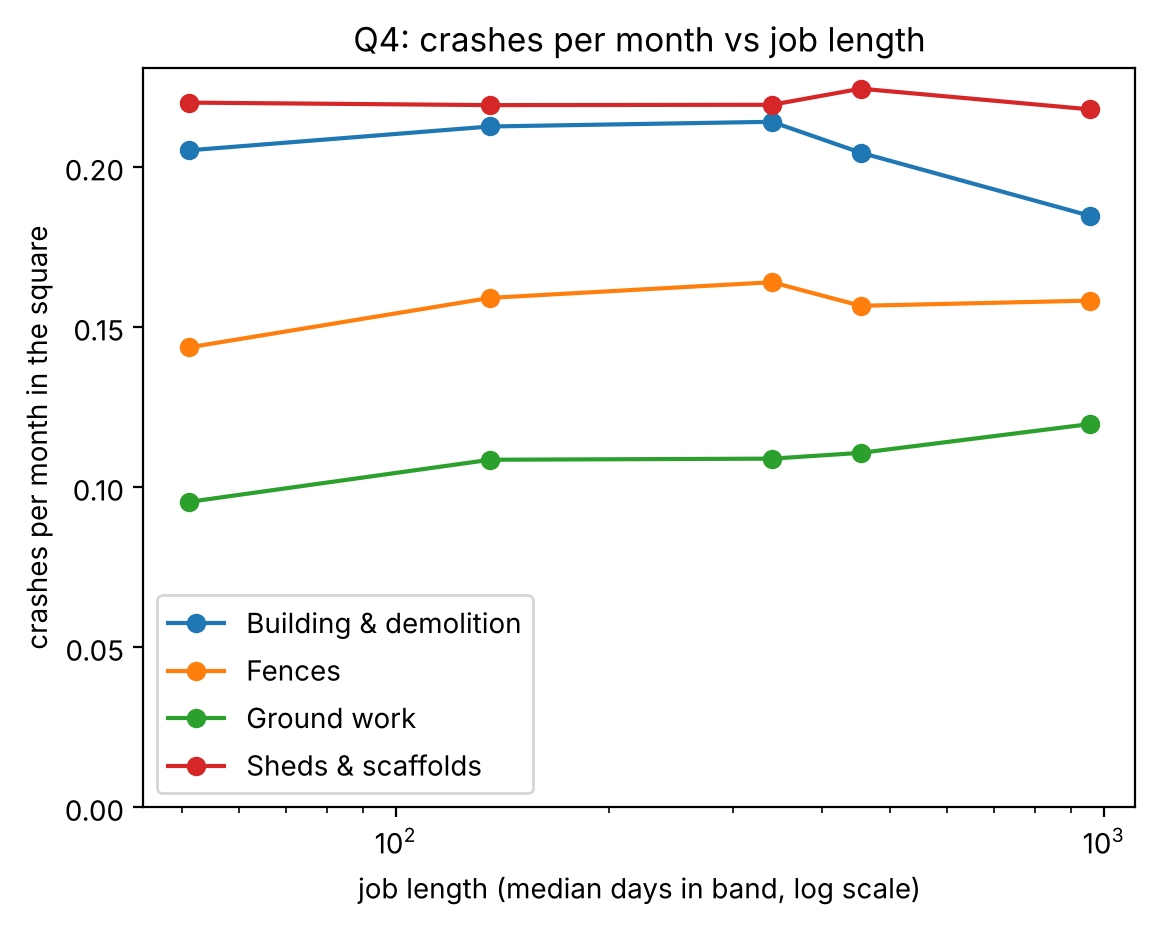

In [ ]:
# x position of each band = the median job length in it, so the points sit at their real length
band_days = jobs.groupby(length_band, observed=True)['days'].median()
# one line of points per family
for name in q4.columns:
    plt.plot(band_days.values, q4[name].values, marker='o', label=name)
# log scale so 1-month and 3-year jobs both fit
plt.xscale('log')
# labels, legend, title
plt.xlabel('job length (median days in band, log scale)')
plt.ylabel('crashes per month in the square')
plt.ylim(bottom=0)
plt.legend()
plt.title('Q4: crashes per month vs job length')
# draw the chart
plt.show()

**What we found (Q4):** no. Inside each family the crash rate stays about the same whether the job lasts under 3 months or over 2 years: sheds & scaffolds 0.218–0.224 crashes per month, fences 0.144–0.164, ground work 0.095–0.120. Building & demolition dips to 0.185 for jobs over 2 years. The big difference is *between* families: sheds and scaffolds sit near 0.22, ground work near 0.11. That comes from *where* they are (sheds and scaffolds line busy streets), which matches Q1, not from how long the job lasts. Limits: these are crashes in the square while the job ran, not crashes caused by it; jobs still running are cut at 31 Oct 2026.

## Q5: Did the work vs no-work crash gap in Manhattan change after congestion pricing (5 Jan 2025), compared with other boroughs?
- **Why ask:** congestion pricing took cars out of lower Manhattan. With less traffic, the extra danger around street work could shrink there but not elsewhere.
- **Data:** the same square compared with itself (as in Q2), year by year: crashes per month in its work months minus its no-work months. Only square-years with at least 3 months of each. Averaged per year for Manhattan and for the other boroughs; a square's borough is the most common borough of its crashes (`boro_mode`).
- **Chart:** grouped column. Lecture 4 chart chooser: comparison over time, few periods (5 years), few categories (2) → column chart.

In [ ]:
# per square, year and work flag: number of months and crashes in them
per_year = (grid.assign(year=grid['month'].dt.year)
            .groupby(['cell', 'year', 'active'])['crashes'].agg(['size', 'sum'])
            .unstack('active', fill_value=0))
# keep square-years with at least 3 work months and 3 no-work months, so one month can't swing it
per_year = per_year[(per_year[('size', True)] >= 3) & (per_year[('size', False)] >= 3)]
# work minus no-work crashes per month: same square, same year
gap = per_year[('sum', True)] / per_year[('size', True)] - per_year[('sum', False)] / per_year[('size', False)]
# Manhattan or not, from each square's most common crash borough
area = gap.index.get_level_values('cell').map(boro_mode).map(lambda b: 'Manhattan' if b == 'MANHATTAN' else 'other boroughs')
# average gap per year and area, and how many squares it is based on
q5 = gap.groupby([gap.index.get_level_values('year'), area]).agg(['mean', 'count']).unstack()
q5.round(4)

mean                    count               
cell Manhattan other boroughs Manhattan other boroughs
year                                                  
2022    0.0190         0.0069      1262           6799
2023   -0.0078         0.0013       630           6575
2024    0.0006        -0.0029       627           6495
2025    0.0171        -0.0026       612           6290
2026   -0.0137        -0.0042       576           5006

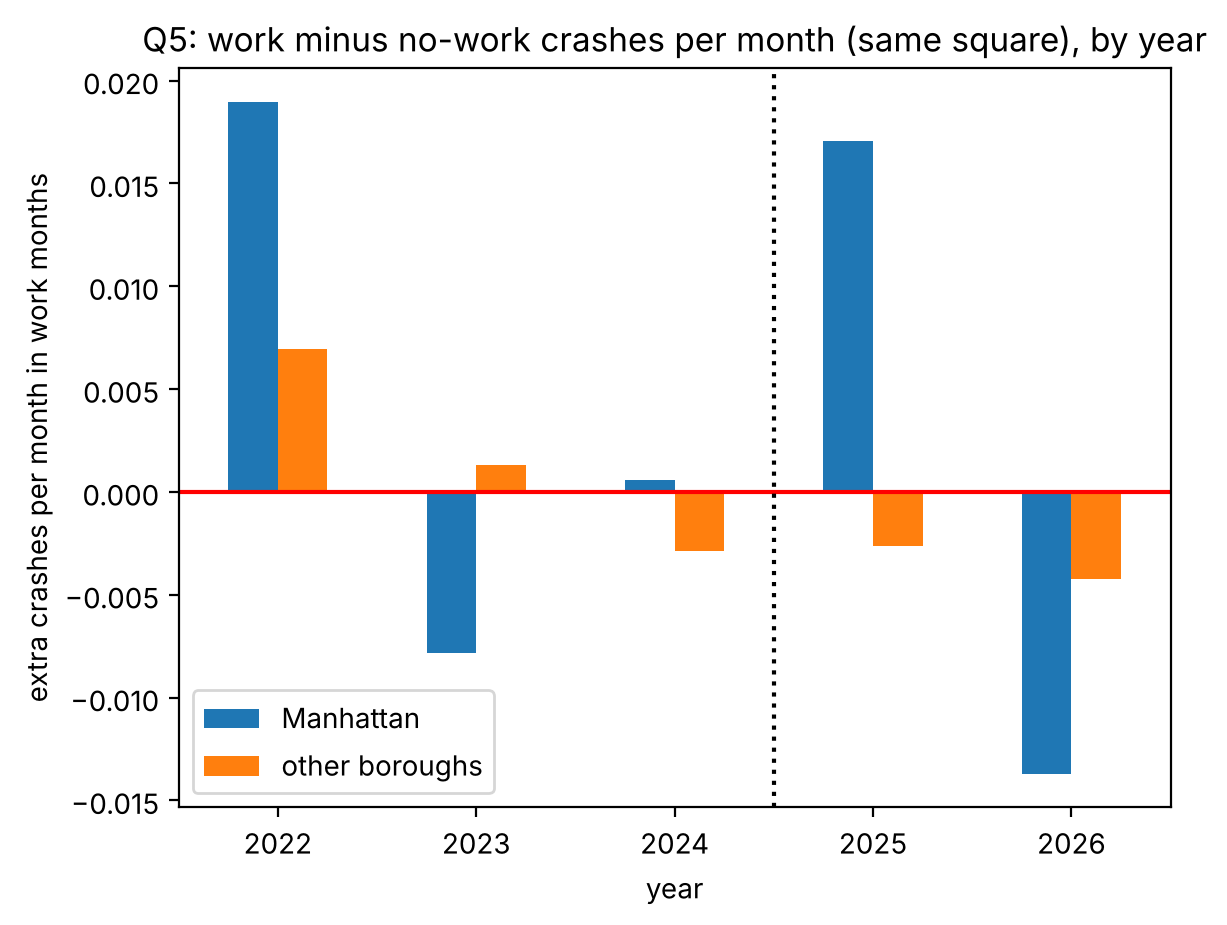

In [ ]:
# grouped columns: Manhattan and other boroughs, side by side for each year
q5['mean'].plot.bar(rot=0, title='Q5: work minus no-work crashes per month (same square), by year')
# legend without a title
plt.legend(title='')
# red line at 0 = no difference between work and no-work months
plt.axhline(0, color='red')
# dotted line between 2024 and 2025: congestion pricing started 5 Jan 2025
plt.axvline(2.5, color='black', linestyle=':')
plt.xlabel('year')
plt.ylabel('extra crashes per month in work months')
# draw the chart
plt.show()

**What we found (Q5):** no change. Manhattan's gap jumps around 0 every year (+0.019 in 2022, −0.008 in 2023, +0.001 in 2024, +0.017 in 2025, −0.014 in 2026), with no shift after congestion pricing. It rests on only about 600 Manhattan squares a year, so it is noisy. The other boroughs stay close to 0 (between −0.004 and +0.007). After congestion pricing, work months are still not clearly more dangerous than no-work months, in Manhattan or elsewhere. Limits: borough level, not the exact pricing zone south of 60th St; 2026 is Jan–Oct only; no traffic counts.

## Q6: Near street work, are the injured more often pedestrians or cyclists?
- **Why ask:** sheds and fences push people off the sidewalk, so if work matters, the mix of who gets hurt should change.
- **Data:** crashes in squares that have work at some point, tagged work / no-work month; share of injured who are pedestrians, cyclists, motorists.
- **Chart:** 100% stacked bar. Lecture 4: composition → stacked bar.

In [101]:
# crashes in squares that had work at some point, with the work/no-work flag for their month
near = df_mv.merge(grid[['cell', 'month', 'active']], on=['cell', 'month'])
# total injured pedestrians, cyclists and motorists, with work vs without
q6 = near.groupby('active')[injury_cols].sum()
# turn counts into % of all injured in that row
q6 = q6.div(q6.sum(axis=1), axis=0) * 100
# show the table
q6

,number_of_pedestrians_injured,number_of_cyclist_injured,number_of_motorist_injured
active,,,
False,21.840531,11.097090,67.062379
True,25.261241,16.003579,58.735180


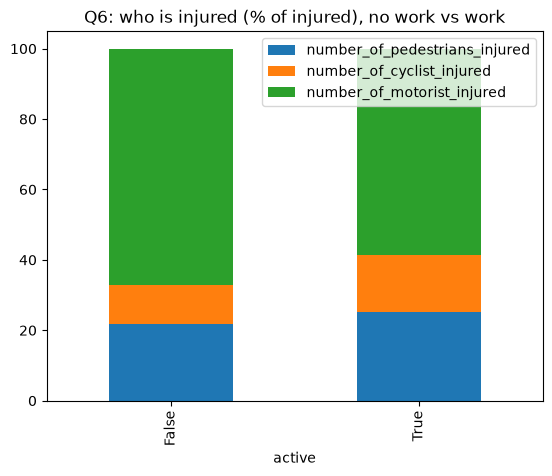

In [102]:
# 100% stacked bars: who makes up the injured, without vs with work
q6.plot.bar(stacked=True, title='Q6: who is injured (% of injured), no work vs work')
# draw the chart
plt.show()

**What we found (Q6):** a clear shift. In work months, pedestrians are 25.3% of the injured (vs 21.8%) and cyclists 16.0% (vs 11.1%); motorists drop from 67.1% to 58.7%. So the *number* of crashes barely changes (Q2), but *who gets hurt* does: pedestrians and cyclists are 41% of injuries near active work vs 33% without. Caveat: cyclist injuries grew over 2022–2026 (e-bikes), and work months are not spread evenly in time, so part of this may be a time trend.

## Q7: Which contributing factors become more common near work?
- **Why ask:** work could change *how* crashes happen (blocked view, obstruction) even if the number barely moves.
- **Data:** share of crashes citing each factor (vehicle 1) in work months minus no-work months, in percentage points; top 10 by size. 'Unspecified' and 'Does Not Apply' are dropped: they describe how the form was filled, not how the crash happened.
- **Chart:** horizontal bar. Lecture 4: ranking with long labels → horizontal bar.

In [103]:
# % of crashes for each reason, separately for work and no-work months
q7 = pd.crosstab(near['contributing_factor_vehicle_1'], near['active'], normalize='columns') * 100
# work % minus no-work %; drop the two "no real reason" values
q7 = (q7[True] - q7[False]).drop(['Unspecified', 'Does Not Apply'])
# the 10 reasons that changed the most (up or down)
q7.loc[q7.abs().nlargest(10).index].sort_values()

contributing_factor_vehicle_1
Unsafe Speed                                            -0.422315
Traffic Control Disregarded                             -0.202398
Alcohol Involvement                                     -0.183269
Pavement Slippery                                       -0.129978
Fell Asleep                                             -0.115213
Unsafe Lane Changing                                     0.112184
Passenger Distraction                                    0.135564
Passing Too Closely                                      0.286421
Pedestrian/Bicyclist/Other Pedestrian Error/Confusion    0.535461
Driver Inattention/Distraction                           0.550541
dtype: float64

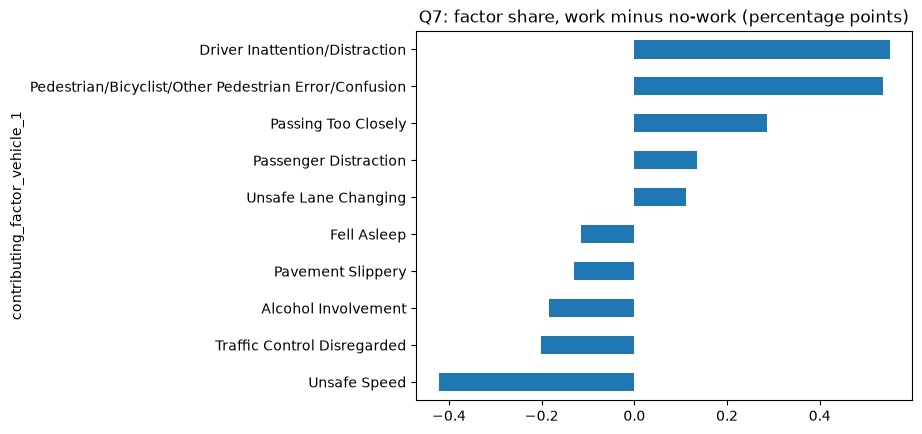

In [104]:
# horizontal bars of those 10 changes
q7.loc[q7.abs().nlargest(10).index].sort_values().plot.barh(title='Q7: factor share, work minus no-work (percentage points)')
# draw the chart
plt.show()

**What we found (Q7):** near active work, crashes blamed on driver inattention (+0.55 points) and pedestrian/cyclist confusion (+0.54) are more common, and so is passing too closely (+0.29). Unsafe speed is less common (−0.42). That fits a crowded, slower street: less speeding, more people squeezed together. All changes are under 1 point, and "View Obstructed" and "Obstruction/Debris" are not in the top 10, so work does not clearly show up as blocked views.

## Q8: Do crashes near work peak during working hours?
- **Why ask:** if the work itself matters, its effect should show when crews and trucks are there (about 7:00–18:00 on weekdays).
- **Data:** weekdays only; share of crashes in each hour, work vs no-work months.
- **Chart:** line, 2 lines. Lecture 4: change over time (24 hours), few lines → line.

In [105]:
# keep weekdays only (Monday=0 ... Friday=4), when work sites are open
week = near[near['crash_date'].dt.day_of_week < 5]
# % of crashes in each hour, separately for work and no-work months
q8 = pd.crosstab(week['hour'], week['active'], normalize='columns') * 100
# readable column names
q8.columns = ['no work', 'work']

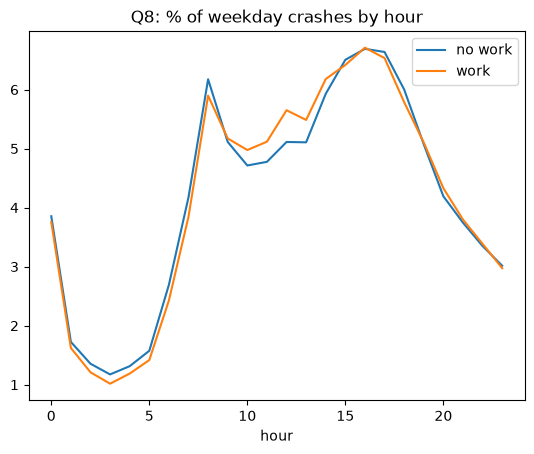

In [106]:
# two lines over the 24 hours: no work vs work
q8.plot(title='Q8: % of weekday crashes by hour')
# draw the chart
plt.show()

**What we found (Q8):** the two lines almost overlap. The work line is a little higher from about 10:00 to 14:00 (midday, when crews and deliveries are on site) and a little lower at the 8:00 and 17:00 rush peaks. The gap is under 1 percentage point per hour, so this is a weak hint, not proof.

## Q9: Are trucks a bigger share of crashes near work, in every borough?
- **Why ask:** construction brings dump trucks, mixers and deliveries.
- **Data:** % of crashes where vehicle 1 is a truck, work vs no-work months, per borough.
- **Chart:** grouped bar. Lecture 4: sub-categories (borough × work) → grouped bar.

In [107]:
# True if the crash's first vehicle is a truck
near['truck'] = near['vehicle'] == 'truck'
# % of crashes with a truck, per borough, work vs no work
q9 = near.groupby(['borough', 'active'])['truck'].mean().unstack() * 100
# show the table
q9

active,False,True
borough,,
BRONX,5.560059,5.116056
BROOKLYN,5.864436,6.604098
MANHATTAN,6.221125,6.668004
QUEENS,5.202929,5.012439
STATEN ISLAND,5.842697,5.235602


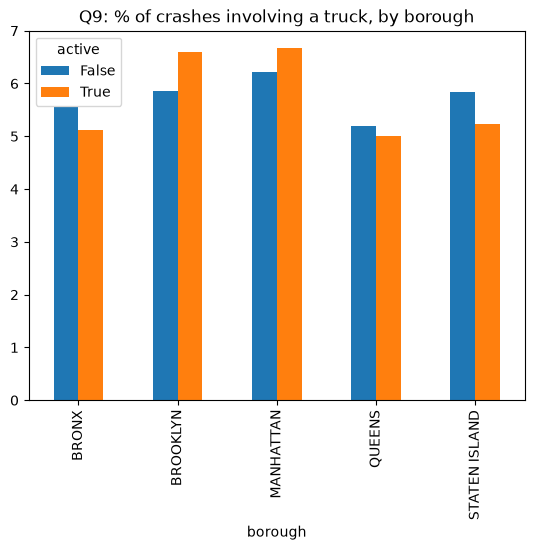

In [108]:
# grouped bars: two bars (no work, work) per borough
q9.plot.bar(title='Q9: % of crashes involving a truck, by borough')
# draw the chart
plt.show()

**What we found (Q9):** no consistent pattern. Trucks are a slightly bigger share near work in Brooklyn (6.6% vs 5.9%) and Manhattan (6.7% vs 6.2%), but slightly smaller in the Bronx, Queens and Staten Island. All gaps are under 1 point, so trucks are not clearly more common near work. Limit: only vehicle 1 is checked.

## Q10: Do squares with sheds up more than 2 years have a higher crash rate, or a higher pedestrian share of injuries, than squares with short-lived sheds?
- **Why ask:** some sidewalk sheds stay up for years. If a long-standing shed makes its square more dangerous, or more dangerous for people on foot, the city has a reason to make owners take them down sooner.
- **Data:** every sidewalk shed job, grouped by how long it stood. For each group: crashes in the shed's square while it stood ÷ months it stood, and pedestrians as % of everyone injured in those crashes (both computed in Q4).
- **Chart:** two column panels. Lecture 4 chart chooser: comparison among a few items (4 length groups) → column chart; one panel per measure because the two have different units.

In [ ]:
# sidewalk shed jobs only
sheds = jobs[jobs['work_type'] == 'Sidewalk Shed']
# how long each shed stood
shed_band = pd.cut(sheds['days'], [0, 182, 365, 730, 10000], labels=['< 6 months', '6–12 months', '1–2 years', '> 2 years'])
# totals per group (crashes, months, pedestrians injured, everyone injured), then the two measures
q10 = sheds.groupby(shed_band, observed=True)[['crashes_in_square', 'job_months', 'ped_injured', 'injured']].sum()
q10['crashes_per_month'] = q10['crashes_in_square'] / q10['job_months']
q10['pedestrian_share'] = q10['ped_injured'] / q10['injured'] * 100
# number of sheds in each group
q10['sheds'] = sheds.groupby(shed_band, observed=True).size()
q10[['sheds', 'crashes_per_month', 'pedestrian_share']].round(3)

,sheds,crashes_per_month,pedestrian_share
days,,,
< 6 months,3860,0.223,27.040
6–12 months,10965,0.222,27.364
1–2 years,5328,0.227,27.541
> 2 years,2795,0.214,26.831


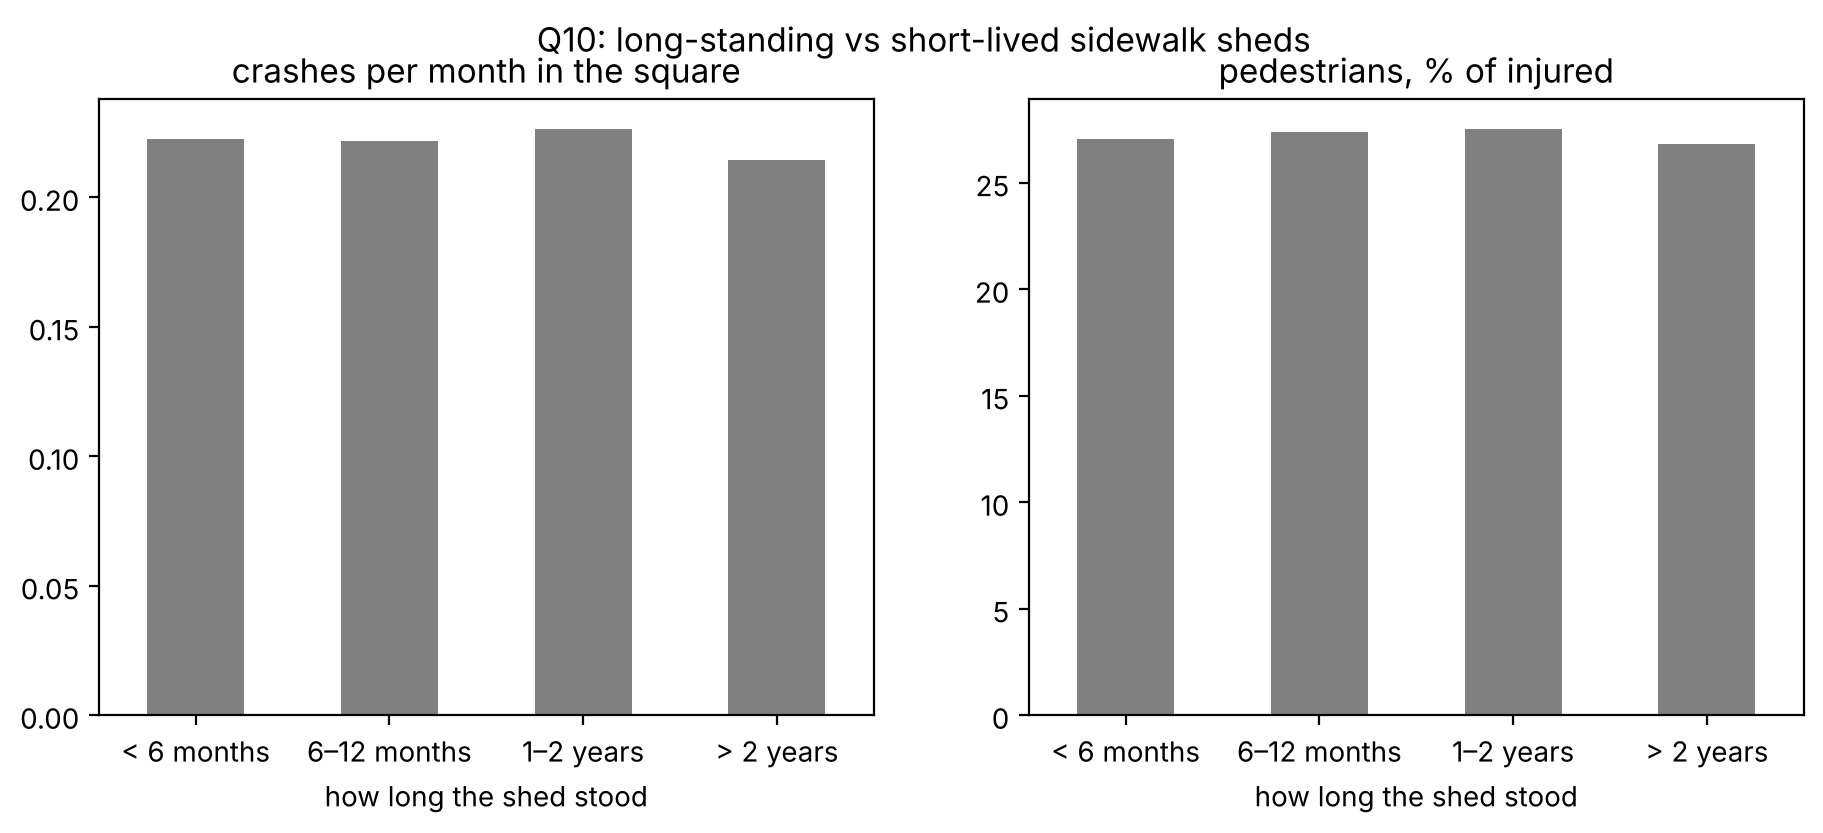

In [ ]:
# two panels side by side: crash rate (left) and pedestrian share (right)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
q10['crashes_per_month'].plot.bar(ax=axes[0], rot=0, color='grey', title='crashes per month in the square')
q10['pedestrian_share'].plot.bar(ax=axes[1], rot=0, color='grey', title='pedestrians, % of injured')
# x label on both panels
for ax in axes:
    ax.set_xlabel('how long the shed stood')
fig.suptitle('Q10: long-standing vs short-lived sidewalk sheds')
# draw the chart
plt.show()

**What we found (Q10):** no. Sheds up more than 2 years see 0.214 crashes per month in their square, against 0.222–0.227 for shorter ones, and pedestrians are 26.8% of the injured against 27.0–27.5%. So a long-standing shed is not more dangerous per month. But it stands far longer: the 2,795 sheds up more than 2 years have 21,561 crashes in their squares while they stood, about as many as the 5,328 sheds that stood 1–2 years (21,646). The risk per month is the same, so the length is what adds up. Limit: association only; a crash near a shed is not necessarily caused by it.

# Story: what we learned

**The question.** Is the street around street work (sheds, scaffolds, fences, demolition) more dangerous while the work is active? It matters because sheds and fences push people off the sidewalk and block drivers' view, and some sheds stay up for years.

**What we expected.** More crashes near active sites, especially pedestrians and cyclists, because work takes space from the sidewalk and the road.

**What surprised us.**
- The first number looked like proof: square-months with work average **0.175** crashes vs **0.132** without (+32%).
- But it is mostly the place. Squares that get lots of work already had almost double the crashes in months with **no** work (Q1).
- Compared with itself, a square's work months are not clearly worse: higher in 38% of squares, lower in 44% (Q2).
- But **who gets hurt** changes: near active work, pedestrians and cyclists are 41% of the injured vs 33% without (Q6). Work is linked with a different mix of victims, not with more crashes.
- No work type stands out (Q3), and trucks are not clearly more common near work (Q9).
- How long work lasts doesn't matter: a square's crashes per month are the same for short and long jobs (Q4), and for short-lived and long-standing sheds, with the same pedestrian share (Q10). A shed up for years is not riskier per month, but its risk lasts for years.
- Congestion pricing did not change the gap between work and no-work months, in Manhattan or elsewhere (Q5).
- Street work is everywhere: 61% of crashes happen in a square that has street work at some point.

**Where our data is limited.**
- Association only. We cannot say work causes or prevents crashes.
- The flag is per month: a 2-day job marks the whole month as active.
- Permit dates are when work is *allowed*, not when it actually happened.
- No traffic or foot-traffic counts, so we can't tell "more crashes" from "more people".
- ~5% of crashes (24,521 of 447,156) have no lat/lon and could not be placed.
- The ~100 m squares are rounded lat/lon, so a site and a crash on the same block can land in neighbouring squares.
- Police-reported crashes only; small crashes may be missing.
- The Q6 shift may partly be a time trend (more e-bike injuries in later years).
- Q5 is borough level, not the exact congestion zone, and 2026 is Jan–Oct only.

**Who could benefit, and what they could do.**
- **NYC DOT / DOB:** target safety work by how risky a *place* is, not by permit count alone, since busy squares are the risk (Q1). Around active sites, protect pedestrians and cyclists first (covered walkways, marked bike detours), because they make up more of the injured there (Q6).
- **DOB sidewalk-shed rules (Q10):** a long-standing shed carries the same risk every month it stays up, so pushing owners to finish repairs and take sheds down sooner removes risk directly.
- **Vision Zero and pedestrian-safety groups:** focus on the busiest corridors (e.g. Midtown) where work and crashes overlap.
- **Journalists and residents:** be careful with "construction = more crashes" headlines; the raw gap is mostly location.

**How this study could be improved.**
- Use day-level permit windows instead of months.
- Use distance to the nearest active site instead of grid squares.
- Add exposure data (traffic volume counts) to get crashes per car or per person.
- Add DOT street construction permits (lane and sidewalk closures), which touch the street more directly.
- Look at crashes month by month before and after a job starts in the same square.

# Team contributions
5 members, so 10 research questions and 10 charts: 2 each. The work was built in pull requests, at least 2 per member, merged in order (see the repo's Pull requests tab). Each part added one question to the site plus one website piece.

| Member | PRs | Research questions (chart) | Data prep for their questions | Website components |
|---|---|---|---|---|
| Yusef Wael Saeed | 1, 10, 11, 12 | **Q1** busy squares without work (scatter) · **Q10** long-standing vs short-lived sidewalk sheds (two column panels) | dataset choice and overview; loading with `$where`; EDA of both datasets; pre-integration cleaning (duplicates, missing values, bad coordinates, borough case, cost outliers); ~100 m grid × month integration; post-integration cleaning; export to `data/`; crashes and injuries in each job's square while it ran (used by Q4 and Q10) | base app: layout, 4 dropdowns, Generate Report callback; final story text; README; deployment |
| Ibrahim Abdelshafy Ibrahim | 2, 3 | **Q3** change in crashes by work type, same square (bar) · **Q5** work vs no-work gap, Manhattan vs other boroughs, before and after congestion pricing (grouped column) | work type per square-month; same-square gap per year, square borough from its crashes | dark dropdown style; search mode (`search.py`) |
| Ibrahim Samer Alalamy | 4, 5 | **Q7** contributing factors near work (horizontal bar) · **Q9** truck share of crashes by borough (grouped bar) | contributing factor: fill "Unspecified", fix "Illnes" typo; vehicle types: 1,008 labels grouped into ~10 | cross-domain map (permit sites + crashes); story section and footer |
| Mostafa Amr Elsallamy | 6, 7 | **Q2** same square, work months vs no-work months (histogram) · **Q4** crashes per month vs job length (scatter) | squares with ≥ 6 months of each kind; job duration with renewals merged, expiry clipped at 2026-10-31; length bands and work-type families | empty-data message; hour × weekday heatmap |
| Hassan Hytham Ibrahim | 8, 9 | **Q6** pedestrians vs cyclists among the injured near work (100% stacked bar) · **Q8** crash hour near work (line) | injuries split by person type; crash hour from `crash_time` | loading spinner and responsive grid; map hover text |

# Prompts used
We used Claude (Anthropic) as an assistant for planning, code and checking. These are the main high-level prompts, in project order (lightly cleaned of typos). Every result was run and checked in this notebook before we kept it.

**Planning and choosing the datasets**
1. "Here is the team role breakdown. Which role is the least work, and which teaches the most?"
2. "Should we pick the questions first or the datasets first?"
3. "Run an arena with different New Yorkers to debate which housing × transportation angle is worth studying with the catalog datasets." → rejected affordable housing × crashes (only shows dense areas), picked street-work permits × crashes.
4. "Give me the links for the 2 datasets to download from the data catalog."
5. "Can the .xlsx data dictionaries replace downloading the datasets?" → no, they only describe the columns.

**EDA, cleaning and integration**
6. "Add EDA cells for both datasets: head, info, missing values, describe, single-feature and relationship charts. Minimal code, one step per cell, no helper functions."
7. "Pre-clean both datasets based on what the EDA found, and justify drop vs impute for each column."
8. "Merge crashes with permits on the same ~100 m grid square, then check the merged table for problems." → found renewals, double-counted crashes, busy squares and unfair time windows; fixed them in Post-merge cleaning.
9. "Explain each cell simply: what each line does, what the output means, what we learned."
10. "Does General Construction having the most crashes mean it is riskier, or is it just the most common permit type?"

**Research questions and story**
11. "Run the arena with a New Yorker and a professional data analyst to get questions out of the data, then turn them into 10 plain-language questions, 2 per member."
12. "Justify every chart choice with the Lecture 4 rules."
13. "Write the story: what we expected, what surprised us, the limits, and who could benefit."

**Website, team split and submission**
14. "Grill me about the Dash website against the project requirements before writing any code."
15. "Test the site in the browser: do the filters, search and Generate Report update every chart?"
16. "Split the finished project into 10 parts, 2 per member, each with one question and one website piece, as pull requests."
17. "What is missing for full completion, and is everything in the criteria ready to submit, like deployment?"
18. "How do I deploy the site on Vercel for free?"
19. "Replace Q4, Q5 and Q10 with questions that use both datasets, and pick each chart with the Lecture 4 chart chooser."

In [111]:
# Export data for the website
# small parquet files in data/ with only the columns the Dash site uses
# make the data/ folder (no error if it already exists)
os.makedirs('data', exist_ok=True)

# work types running in each square-month, e.g. "Construction Fence|Sidewalk Shed"
types_now = jobs.explode('month')[['cell', 'month', 'work_type']].drop_duplicates().sort_values('work_type')
types_now = types_now.groupby(['cell', 'month'])['work_type'].agg('|'.join).rename('work_types').reset_index()

# one row per crash; work_square = its square has street work at some point (same rows as `near`)
crash_out = df_mv.merge(grid[['cell', 'month', 'active']], on=['cell', 'month'], how='left')
crash_out['work_square'] = crash_out['active'].notna()
crash_out['active'] = crash_out['active'].eq(True)
crash_out = crash_out.merge(types_now, on=['cell', 'month'], how='left')

# build the small crash table: only the columns the site needs, in compact types
crashes_web = pd.DataFrame({
    'date': crash_out['crash_date'],
    'month': crash_out['month'].dt.to_timestamp(),
    'year': crash_out['crash_date'].dt.year.astype('int16'),
    'hour': crash_out['hour'].astype('int8'),
    'weekday': crash_out['crash_date'].dt.day_of_week.astype('int8'),  # 0 = Monday
    'borough': crash_out['borough'].astype('category'),
    'lat': crash_out['latitude'].astype('float32'),
    'lon': crash_out['longitude'].astype('float32'),
    'active': crash_out['active'],
    'work_square': crash_out['work_square'],
    'work_types': crash_out['work_types'].fillna('').astype('category'),
    'ped_inj': crash_out['number_of_pedestrians_injured'].astype('int8'),
    'cyc_inj': crash_out['number_of_cyclist_injured'].astype('int8'),
    'mot_inj': crash_out['number_of_motorist_injured'].astype('int8'),
    'factor': crash_out['contributing_factor_vehicle_1'].astype('category'),
    'vehicle_group': crash_out['vehicle'].astype('category'),
})
# save it as a parquet file (small and fast to load)
crashes_web.to_parquet('data/crashes.parquet', index=False)

# one row per street-work job; lat/lon = centre of its ~100 m square, ZIP/borough from its first permit
job_place = dob.groupby('job_filing_number')[['borough', 'zip_code']].first()
square_lat_lon = jobs['cell'].str.split(',', expand=True).astype('float32')
# build the small jobs table the same way
jobs_web = pd.DataFrame({
    'work_type': jobs['work_type'].astype('category'),
    'start': jobs['issued_date'],
    'end': jobs['expired_date'],
    'days': jobs['days'].astype('int32'),
    'year': jobs['issued_date'].dt.year.astype('int16'),
    'borough': jobs['job_filing_number'].map(job_place['borough']).astype('category'),
    'zip_code': jobs['job_filing_number'].map(job_place['zip_code']).astype('int32'),
    'lat': square_lat_lon[0],
    'lon': square_lat_lon[1],
})
# save it
jobs_web.to_parquet('data/jobs.parquet', index=False)

# per square-month: crashes with >= 1 pedestrian / cyclist / motorist injured
flags = near[['cell', 'month']].assign(ped=near[injury_cols[0]] > 0, cyc=near[injury_cols[1]] > 0, mot=near[injury_cols[2]] > 0)
person_counts = flags.groupby(['cell', 'month'])[['ped', 'cyc', 'mot']].sum().reset_index()
sq = grid.merge(person_counts, on=['cell', 'month'], how='left').fillna({'ped': 0, 'cyc': 0, 'mot': 0})
sq['year'] = sq['month'].dt.year

# square x year, work months and no-work months summed separately
sq = sq.groupby(['cell', 'year', 'active']).agg(
    months=('crashes', 'size'), crashes=('crashes', 'sum'),
    ped_crashes=('ped', 'sum'), cyc_crashes=('cyc', 'sum'), mot_crashes=('mot', 'sum'),
).unstack('active', fill_value=0)
sq.columns = [name + ('_work' if is_active else '_nowork') for name, is_active in sq.columns]
sq = sq.rename(columns={'months_work': 'work_months', 'months_nowork': 'nowork_months'}).astype('int16').reset_index()

# square borough = mode of its crash boroughs (permit borough if it has no crashes); main_type is used by Q3
sq['borough'] = sq['cell'].map(boro_mode).fillna(sq['cell'].map(dob.groupby('cell')['borough'].first())).astype('category')
sq['main_type'] = sq['cell'].map(cell_type).astype('category')
sq['cell'] = sq['cell'].astype('category')
sq['year'] = sq['year'].astype('int16')
# save it
sq.to_parquet('data/squares.parquet', index=False)

# check: size of each saved file, row counts, and borough names
for name in os.listdir('data'):
    print(name, round(os.path.getsize('data/' + name) / 1e6, 1), 'MB')
print(len(crashes_web), len(jobs_web), len(sq))
print(sorted(crashes_web['borough'].dropna().unique()), sorted(jobs_web['borough'].unique()))

crashes.parquet 3.6 MB
jobs.parquet 1.3 MB
squares.parquet 0.8 MB
416353 155144 144835
['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND'] ['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND']
